
# 🦟 DengueGuard AI
### AI-Powered Urban Dengue Outbreak Prediction System

**EDU AI Engineering Hackathon 2026**
**Phase 1: 24-Hour Remote Qualifier**

---

## 🎯 Project Objective

To develop an AI-powered early warning system that predicts
future Dengue outbreak risks at ward level using historical
weather data, environmental factors, and dengue case records.

The system aims to provide a 2–4 week early warning window
for public health authorities.

## 🧠 Core Technologies

- Python
- Pandas & NumPy
- Scikit-learn
- XGBoost
- CatBoost
- LightGBM
- Matplotlib & Seaborn
- Streamlit

## 📌 Project Workflow

1. Dataset Loading & Understanding
2. Exploratory Data Analysis (EDA)
3. Data Cleaning & Preprocessing
4. Ward-wise Feature Engineering
5. Multi-Week Rainfall Lag Calculation
6. Future Dengue Target Engineering
7. Chronological Train-Validation-Test Split
8. Model Training & Comparison
9. Hyperparameter Optimization
10. Model Evaluation
11. Risk Classification
12. Streamlit Dashboard Development

## 🎯 Prediction Targets

- Dengue Cases after 2 Weeks
- Dengue Cases after 4 Weeks

## 📊 Evaluation Metrics

- MAE
- RMSE
- R² Score
- Precision
- Recall
- F1 Score

---
**Developed for EDU AI Engineering Hackathon 2026**


**Google Drive Connection**

In [1]:

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive Connected Successfully!")


Mounted at /content/drive
Google Drive Connected Successfully!


**Create Professional Project Folder Structure**

In [2]:
import os
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/DengueGuard_AI"
)

FOLDERS = [
    "data/raw",
    "data/cleaned",
    "data/processed",
    "models",
    "notebooks",
    "reports",
    "visualizations",
    "predictions",
    "logs"
]

for folder in FOLDERS:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

RAW_DIR = PROJECT_DIR / "data/raw"
CLEANED_DIR = PROJECT_DIR / "data/cleaned"
PROCESSED_DIR = PROJECT_DIR / "data/processed"
MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"
VISUAL_DIR = PROJECT_DIR / "visualizations"
PREDICTION_DIR = PROJECT_DIR / "predictions"
LOG_DIR = PROJECT_DIR / "logs"

print("Project Structure Created Successfully!")
print("Project Location:", PROJECT_DIR)

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(str(PROJECT_DIR), "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")


Project Structure Created Successfully!
Project Location: /content/drive/MyDrive/DengueGuard_AI
DengueGuard_AI/
  data/
    raw/
    cleaned/
    processed/
  models/
  notebooks/
  reports/
  visualizations/
  predictions/
  logs/


**Upload Dataset and Save Permanently**

In [3]:

import shutil

DATASET_NAME = (
    "hackathon_preli_dataset - "
    "bangladesh_dengue_large_dataset.csv"
)

RAW_DATA_PATH = RAW_DIR / DATASET_NAME

if RAW_DATA_PATH.exists():

    print("Dataset already exists in Google Drive!")
    print(RAW_DATA_PATH)

else:

    from google.colab import files

    print("Please upload your original CSV dataset.")

    uploaded = files.upload()

    uploaded_name = next(iter(uploaded))

    source_path = Path("/content") / uploaded_name

    shutil.copy2(
        source_path,
        RAW_DATA_PATH
    )

    print("Dataset uploaded and backed up to Drive!")

print("Dataset Backup:", RAW_DATA_PATH)


Please upload your original CSV dataset.


Saving hackathon_preli_dataset - bangladesh_dengue_large_dataset.csv to hackathon_preli_dataset - bangladesh_dengue_large_dataset.csv
Dataset uploaded and backed up to Drive!
Dataset Backup: /content/drive/MyDrive/DengueGuard_AI/data/raw/hackathon_preli_dataset - bangladesh_dengue_large_dataset.csv


**Load Dataset from Google Drive**

In [4]:

import pandas as pd
import numpy as np

df = pd.read_csv(RAW_DATA_PATH)

print("Dataset Loaded Successfully!")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

# Save initial dataset backup
df.to_csv(
    RAW_DIR / "original_dataset_backup.csv",
    index=False
)

print("Original dataset backup saved to Google Drive!")


Dataset Loaded Successfully!
Rows: 31320
Columns: 12


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0


Original dataset backup saved to Google Drive!


**Install and Import Libraries**

In [5]:

%pip install -q xgboost lightgbm catboost joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings
from datetime import datetime

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All libraries are ready!")


All libraries are ready!


**Create Automatic Save Functions**

In [6]:
import os
import json
import joblib
from datetime import datetime

def save_dataframe(dataframe, filename, folder=PROCESSED_DIR):

    path = folder / filename

    dataframe.to_csv(path, index=False)

    print(f"Saved successfully: {path}")

    return path

def save_model(model, filename):

    path = MODEL_DIR / filename

    joblib.dump(model, path)

    print(f"Model saved: {path}")

    return path

def save_json(data, filename, folder=REPORT_DIR):

    path = folder / filename

    with open(path, "w") as f:
        json.dump(data, f, indent=4, default=str)

    print(f"Report saved: {path}")

    return path

def save_figure(filename):

    path = VISUAL_DIR / filename

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Figure saved: {path}")

    return path

print("Automatic Save Functions Ready!")


Automatic Save Functions Ready!


**Project Progress Tracker**

In [7]:
progress = {
    "project": "DengueGuard AI",
    "hackathon": "EDU AI Engineering Hackathon 2026",

    "completed": [
        "Project Setup",
        "Google Drive Connection",
        "Dataset Backup",
        "Library Installation",
        "Automatic Save Functions"
    ],

    "pending": [
        "Exploratory Data Analysis",
        "Data Cleaning",
        "Feature Engineering",
        "Rainfall Lag Engineering",
        "Future Target Engineering",
        "Model Training",
        "Hyperparameter Tuning",
        "Model Evaluation",
        "Streamlit Dashboard"
    ]
}

save_json(progress, "project_progress.json")

print("Project Progress Saved Successfully!")


Report saved: /content/drive/MyDrive/DengueGuard_AI/reports/project_progress.json
Project Progress Saved Successfully!


**Dataset Loading & Initial Inspection**

In [8]:
import pandas as pd
import numpy as np

DATASET_PATH = (
    RAW_DIR /
    "hackathon_preli_dataset - bangladesh_dengue_large_dataset.csv"
)

df = pd.read_csv(DATASET_PATH)

print("=" * 55)
print("       DENGUEGUARD AI - DATASET INSPECTION")
print("=" * 55)

print("\n1. Dataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Column Names:")
print(df.columns.tolist())

print("\n3. First 5 Records:")
display(df.head())

print("\n4. Last 5 Records:")
display(df.tail())

print("\n5. Dataset Information:")
df.info()

print("\n6. Date Range:")
print("Start:", df["date"].min())
print("End:", df["date"].max())

print("\nInspection Completed!")


       DENGUEGUARD AI - DATASET INSPECTION

1. Dataset Shape:
Rows: 31320
Columns: 12

2. Column Names:
['date', 'city', 'ward_id', 'population_density_sqkm', 'water_logging_risk_index', 'sanitation_score', 'avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'relative_humidity_pct', 'dengue_cases']

3. First 5 Records:


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,59.24,0
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,61.63,0
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,60.50,0
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,69.02,0
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,60.50,0



4. Last 5 Records:


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,relative_humidity_pct,dengue_cases
31315,2025-12-01,Narayanganj,NCC_Ward_05,40043,0.9,0.34,17.73,23.49,13.06,9.53,53.21,0
31316,2025-12-08,Narayanganj,NCC_Ward_05,40043,0.9,0.34,20.54,24.74,15.85,0.13,67.46,0
31317,2025-12-15,Narayanganj,NCC_Ward_05,40043,0.9,0.34,21.98,27.62,15.08,8.24,65.93,0
31318,2025-12-22,Narayanganj,NCC_Ward_05,40043,0.9,0.34,22.23,26.90,18.41,4.11,57.05,0
31319,2025-12-29,Narayanganj,NCC_Ward_05,40043,0.9,0.34,21.76,26.08,16.00,0.51,55.04,0



5. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31320 entries, 0 to 31319
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      31320 non-null  object 
 1   city                      31320 non-null  object 
 2   ward_id                   31320 non-null  object 
 3   population_density_sqkm   31320 non-null  int64  
 4   water_logging_risk_index  31320 non-null  float64
 5   sanitation_score          31320 non-null  float64
 6   avg_temp_c                31320 non-null  float64
 7   max_temp_c                31320 non-null  float64
 8   min_temp_c                31320 non-null  float64
 9   rainfall_mm               31320 non-null  float64
 10  relative_humidity_pct     31320 non-null  float64
 11  dengue_cases              31320 non-null  int64  
dtypes: float64(7), int64(2), object(3)
memory usage: 2.9+ MB

6. Date Range:
Start: 2016-01-04


**Data Quality Audit**

In [9]:
# 1. Convert date into datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# 2. Basic quality checks
print("=" * 55)
print("          DATA QUALITY AUDIT")
print("=" * 55)

print("\n1. Missing Values:")
print(df.isnull().sum())

print("\n2. Duplicate Rows:")
print(df.duplicated().sum())

print("\n3. Duplicate Ward-Date Records:")
print(df.duplicated(subset=["city", "ward_id", "date"]).sum())

print("\n4. Unique Cities:")
print(df["city"].nunique())
print(sorted(df["city"].unique()))

print("\n5. Unique Wards:")
print(df["ward_id"].nunique())

print("\n6. Date Conversion:")
print("Date dtype:", df["date"].dtype)
print("Invalid dates:", df["date"].isna().sum())

# 3. Numeric range inspection
numeric_cols = df.select_dtypes(include=np.number).columns

print("\n7. Numeric Column Statistics:")
display(df[numeric_cols].describe().T)

# 4. Weekly continuity check per ward
weekly_gaps = []

for (city, ward), group in df.groupby(["city", "ward_id"]):
    dates = group["date"].sort_values().dropna()
    gaps = dates.diff().dt.days

    unusual = gaps[gaps != 7].dropna()

    if len(unusual) > 0:
        weekly_gaps.append({
            "city": city,
            "ward_id": ward,
            "unusual_gaps": len(unusual),
            "gap_days": sorted(unusual.unique().tolist())
        })

print("\n8. Weekly Date Continuity:")
print("Wards with unusual date gaps:", len(weekly_gaps))

if weekly_gaps:
    display(pd.DataFrame(weekly_gaps).head(20))
else:
    print("All wards have consistent 7-day intervals.")

print("\nDATA QUALITY AUDIT COMPLETED!")

          DATA QUALITY AUDIT

1. Missing Values:
date                        0
city                        0
ward_id                     0
population_density_sqkm     0
water_logging_risk_index    0
sanitation_score            0
avg_temp_c                  0
max_temp_c                  0
min_temp_c                  0
rainfall_mm                 0
relative_humidity_pct       0
dengue_cases                0
dtype: int64

2. Duplicate Rows:
0

3. Duplicate Ward-Date Records:
0

4. Unique Cities:
5
['Chattogram', 'Dhaka North', 'Dhaka South', 'Gazipur', 'Narayanganj']

5. Unique Wards:
60

6. Date Conversion:
Date dtype: datetime64[ns]
Invalid dates: 0

7. Numeric Column Statistics:


,count,mean,std,min,25%,50%,75%,max
population_density_sqkm,31320.0,43157.733333,14865.377799,18314.00,30573.5000,42854.000,54168.2500,74252.00
water_logging_risk_index,31320.0,0.579333,0.237903,0.22,0.3775,0.545,0.8200,0.94
sanitation_score,31320.0,0.554667,0.191597,0.25,0.3800,0.570,0.7125,0.88
avg_temp_c,31320.0,26.922804,4.482042,15.74,22.8800,26.850,31.0225,37.51
max_temp_c,31320.0,31.889061,4.516627,23.12,27.8500,31.505,35.9900,40.79
min_temp_c,31320.0,21.949425,4.527965,13.06,18.0000,21.670,25.9700,31.64
rainfall_mm,31320.0,35.630268,50.237519,0.00,0.9200,8.370,59.4200,268.83
relative_humidity_pct,31320.0,71.176132,12.968610,41.84,60.4675,68.220,83.9800,99.00
dengue_cases,31320.0,2.636398,4.607737,0.00,0.0000,0.000,4.0000,41.00



8. Weekly Date Continuity:
Wards with unusual date gaps: 0
All wards have consistent 7-day intervals.

DATA QUALITY AUDIT COMPLETED!


**Clean Dataset**

In [10]:
# ============================================
# STEP 10: DATA CLEANING & VALIDATION
# ============================================

# Keep original dataset safe
df_clean = df.copy()

# 1. Sort chronologically within each ward
df_clean = df_clean.sort_values(
    by=["city", "ward_id", "date"]
).reset_index(drop=True)

# 2. Validate numeric columns
numeric_columns = [
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score",
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct",
    "dengue_cases"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

# 3. Check logical conditions
print("=" * 55)
print("       DATA CLEANING & VALIDATION")
print("=" * 55)

print("\n1. Invalid Numeric Values:")
print(df_clean[numeric_columns].isna().sum())

print("\n2. Negative Values:")
for col in numeric_columns:
    print(f"{col}: {(df_clean[col] < 0).sum()}")

print("\n3. Temperature Consistency:")
invalid_temp = (
    (df_clean["min_temp_c"] > df_clean["avg_temp_c"]) |
    (df_clean["avg_temp_c"] > df_clean["max_temp_c"])
)
print("Invalid temperature records:", invalid_temp.sum())

print("\n4. Humidity Outside 0-100:")
invalid_humidity = (
    (df_clean["relative_humidity_pct"] < 0) |
    (df_clean["relative_humidity_pct"] > 100)
)
print("Invalid humidity records:", invalid_humidity.sum())

print("\n5. Risk/Sanitation Score Outside 0-1:")
for col in ["water_logging_risk_index", "sanitation_score"]:
    invalid = (
        (df_clean[col] < 0) |
        (df_clean[col] > 1)
    )
    print(f"{col}: {invalid.sum()}")

print("\n6. Final Dataset Shape:")
print(df_clean.shape)

# 4. Save cleaned dataset to Google Drive
CLEANED_DATA_PATH = CLEANED_DIR / "dengue_cleaned.csv"

save_dataframe(
    df_clean,
    "dengue_cleaned.csv",
    folder=CLEANED_DIR
)

print("\nCleaned dataset saved at:")
print(CLEANED_DATA_PATH)

print("\nSTEP 10 COMPLETED!")

       DATA CLEANING & VALIDATION

1. Invalid Numeric Values:
population_density_sqkm     0
water_logging_risk_index    0
sanitation_score            0
avg_temp_c                  0
max_temp_c                  0
min_temp_c                  0
rainfall_mm                 0
relative_humidity_pct       0
dengue_cases                0
dtype: int64

2. Negative Values:
population_density_sqkm: 0
water_logging_risk_index: 0
sanitation_score: 0
avg_temp_c: 0
max_temp_c: 0
min_temp_c: 0
rainfall_mm: 0
relative_humidity_pct: 0
dengue_cases: 0

3. Temperature Consistency:
Invalid temperature records: 0

4. Humidity Outside 0-100:
Invalid humidity records: 0

5. Risk/Sanitation Score Outside 0-1:
water_logging_risk_index: 0
sanitation_score: 0

6. Final Dataset Shape:
(31320, 12)
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/cleaned/dengue_cleaned.csv

Cleaned dataset saved at:
/content/drive/MyDrive/DengueGuard_AI/data/cleaned/dengue_cleaned.csv

STEP 10 COMPLETED!


**Lag Features & Forecasting Targets**

In [11]:
df_features = df_clean.copy()

# Ensure chronological order
df_features = df_features.sort_values(
    ["city", "ward_id", "date"]
).reset_index(drop=True)

group_cols = ["city", "ward_id"]

# 1. Future forecasting targets
df_features["target_2week"] = (
    df_features.groupby(group_cols)["dengue_cases"].shift(-2)
)

df_features["target_4week"] = (
    df_features.groupby(group_cols)["dengue_cases"].shift(-4)
)

# 2. Dengue historical lag features
for lag in [1, 2, 4, 8]:
    df_features[f"dengue_lag_{lag}"] = (
        df_features.groupby(group_cols)["dengue_cases"].shift(lag)
    )

# 3. Rainfall rolling features
for window in [2, 4]:
    df_features[f"rainfall_sum_{window}w"] = (
        df_features.groupby(group_cols)["rainfall_mm"]
        .transform(
            lambda s: s.rolling(window=window, min_periods=window).sum()
        )
    )

# 4. Weather historical lag features
weather_cols = [
    "avg_temp_c",
    "relative_humidity_pct",
    "rainfall_mm"
]

for col in weather_cols:
    for lag in [1, 2]:
        df_features[f"{col}_lag_{lag}"] = (
            df_features.groupby(group_cols)[col].shift(lag)
        )

# 5. Calendar features
df_features["month"] = df_features["date"].dt.month
df_features["week_of_year"] = (
    df_features["date"].dt.isocalendar().week.astype(int)
)

# 6. Check generated features
print("=" * 55)
print("       FEATURE ENGINEERING RESULTS")
print("=" * 55)

print("\nDataset Shape:", df_features.shape)

print("\nGenerated Target Columns:")
print(["target_2week", "target_4week"])

print("\nGenerated Lag/Rolling Features:")
generated_features = [
    col for col in df_features.columns
    if "lag_" in col or "sum_" in col
]
print(generated_features)

print("\nMissing Values in New Features:")
new_columns = (
    ["target_2week", "target_4week"] +
    generated_features
)
print(df_features[new_columns].isnull().sum())

print("\nFirst 10 Records:")
display(df_features.head(10))

# 7. Save feature-engineered dataset
save_dataframe(
    df_features,
    "dengue_feature_engineered.csv",
    folder=PROCESSED_DIR
)

print("\nFeature-engineered dataset saved successfully!")

       FEATURE ENGINEERING RESULTS

Dataset Shape: (31320, 28)

Generated Target Columns:
['target_2week', 'target_4week']

Generated Lag/Rolling Features:
['dengue_lag_1', 'dengue_lag_2', 'dengue_lag_4', 'dengue_lag_8', 'rainfall_sum_2w', 'rainfall_sum_4w', 'avg_temp_c_lag_1', 'avg_temp_c_lag_2', 'relative_humidity_pct_lag_1', 'relative_humidity_pct_lag_2', 'rainfall_mm_lag_1', 'rainfall_mm_lag_2']

Missing Values in New Features:
target_2week                   120
target_4week                   240
dengue_lag_1                    60
dengue_lag_2                   120
dengue_lag_4                   240
dengue_lag_8                   480
rainfall_sum_2w                 60
rainfall_sum_4w                180
avg_temp_c_lag_1                60
avg_temp_c_lag_2               120
relative_humidity_pct_lag_1     60
relative_humidity_pct_lag_2    120
rainfall_mm_lag_1               60
rainfall_mm_lag_2              120
dtype: int64

First 10 Records:


,date,city,ward_id,population_density_sqkm,water_logging_risk_index,sanitation_score,avg_temp_c,max_temp_c,min_temp_c,rainfall_mm,...,rainfall_sum_2w,rainfall_sum_4w,avg_temp_c_lag_1,avg_temp_c_lag_2,relative_humidity_pct_lag_1,relative_humidity_pct_lag_2,rainfall_mm_lag_1,rainfall_mm_lag_2,month,week_of_year
0,2016-01-04,Chattogram,CCC_Ward_01,64024,0.87,0.46,18.32,26.54,14.13,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1
1,2016-01-11,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.24,26.95,16.71,2.02,...,2.02,NaN,18.32,NaN,59.24,NaN,0.00,NaN,1,2
2,2016-01-18,Chattogram,CCC_Ward_01,64024,0.87,0.46,20.94,25.05,14.84,0.00,...,2.02,NaN,21.24,18.32,61.63,59.24,2.02,0.00,1,3
3,2016-01-25,Chattogram,CCC_Ward_01,64024,0.87,0.46,21.75,27.20,17.58,1.52,...,1.52,3.54,20.94,21.24,60.50,61.63,0.00,2.02,1,4
4,2016-02-01,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.39,28.02,16.98,0.94,...,2.46,4.48,21.75,20.94,69.02,60.50,1.52,0.00,2,5
5,2016-02-08,Chattogram,CCC_Ward_01,64024,0.87,0.46,24.55,28.48,19.81,4.17,...,5.11,6.63,22.39,21.75,60.50,69.02,0.94,1.52,2,6
6,2016-02-15,Chattogram,CCC_Ward_01,64024,0.87,0.46,23.56,30.11,18.51,8.19,...,12.36,14.82,24.55,22.39,49.88,60.50,4.17,0.94,2,7
7,2016-02-22,Chattogram,CCC_Ward_01,64024,0.87,0.46,22.66,29.88,19.23,3.61,...,11.80,16.91,23.56,24.55,52.70,49.88,8.19,4.17,2,8
8,2016-02-29,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.22,29.47,19.23,5.89,...,9.50,21.86,22.66,23.56,60.54,52.70,3.61,8.19,2,9
9,2016-03-07,Chattogram,CCC_Ward_01,64024,0.87,0.46,25.71,31.31,21.56,0.00,...,5.89,17.69,25.22,22.66,55.06,60.54,5.89,3.61,3,10


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/dengue_feature_engineered.csv

Feature-engineered dataset saved successfully!


**Prepare 2-Week & 4-Week Datasets**

In [12]:
# Features available at prediction time
feature_columns = [
    "city",
    "ward_id",
    "population_density_sqkm",
    "water_logging_risk_index",
    "sanitation_score",
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "rainfall_mm",
    "relative_humidity_pct",
    "dengue_cases",
    "dengue_lag_1",
    "dengue_lag_2",
    "dengue_lag_4",
    "dengue_lag_8",
    "rainfall_sum_2w",
    "rainfall_sum_4w",
    "avg_temp_c_lag_1",
    "avg_temp_c_lag_2",
    "relative_humidity_pct_lag_1",
    "relative_humidity_pct_lag_2",
    "rainfall_mm_lag_1",
    "rainfall_mm_lag_2",
    "month",
    "week_of_year"
]


model_data_2w = df_features[
    ["date"] + feature_columns + ["target_2week"]
].dropna().copy()

model_data_4w = df_features[
    ["date"] + feature_columns + ["target_4week"]
].dropna().copy()

# Sort chronologically
model_data_2w = model_data_2w.sort_values("date").reset_index(drop=True)
model_data_4w = model_data_4w.sort_values("date").reset_index(drop=True)

# Save both datasets
save_dataframe(
    model_data_2w,
    "dengue_2week_model_data.csv",
    folder=PROCESSED_DIR
)

save_dataframe(
    model_data_4w,
    "dengue_4week_model_data.csv",
    folder=PROCESSED_DIR
)

# Results
print("=" * 55)
print("       MODEL DATASET PREPARATION")
print("=" * 55)

print("\n2-Week Dataset:")
print("Shape:", model_data_2w.shape)
print("Missing values:", model_data_2w.isna().sum().sum())
print("Date range:", model_data_2w["date"].min(), "to", model_data_2w["date"].max())

print("\n4-Week Dataset:")
print("Shape:", model_data_4w.shape)
print("Missing values:", model_data_4w.isna().sum().sum())
print("Date range:", model_data_4w["date"].min(), "to", model_data_4w["date"].max())

print("\nFeature Count:", len(feature_columns))
print("\nSTEP 12 COMPLETED!")

Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/dengue_2week_model_data.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/dengue_4week_model_data.csv
       MODEL DATASET PREPARATION

2-Week Dataset:
Shape: (30720, 27)
Missing values: 0
Date range: 2016-02-29 00:00:00 to 2025-12-15 00:00:00

4-Week Dataset:
Shape: (30600, 27)
Missing values: 0
Date range: 2016-02-29 00:00:00 to 2025-12-01 00:00:00

Feature Count: 25

STEP 12 COMPLETED!


**Exploratory Data Analysis (EDA)**

**Dengue Cases Distribution**

       DENGUE CASES DISTRIBUTION

1. Dengue Cases Statistics:


,dengue_cases
count,31320.000000
mean,2.636398
std,4.607737
min,0.000000
25%,0.000000
50%,0.000000
75%,4.000000
max,41.000000



2. Zero Case Records:
18176

3. Non-zero Case Records:
13144

4. Percentage of Zero Cases:
58.03 %
Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/dengue_cases_distribution.png


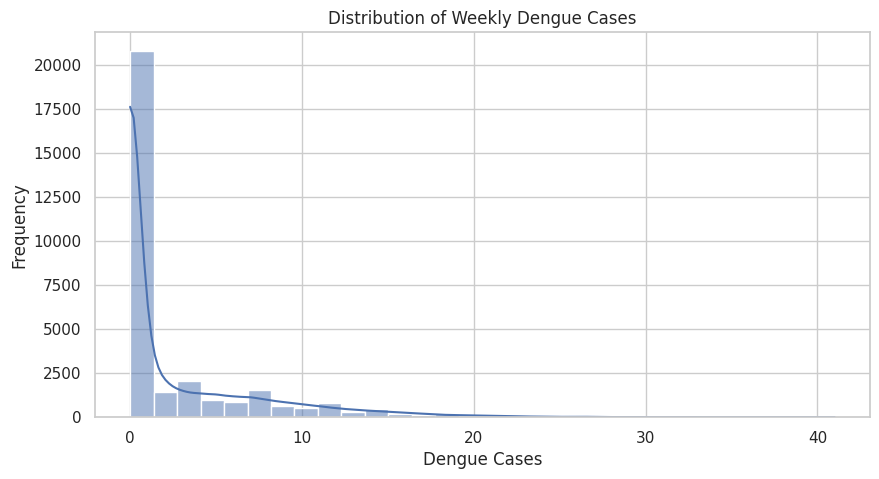

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/dengue_cases_boxplot.png


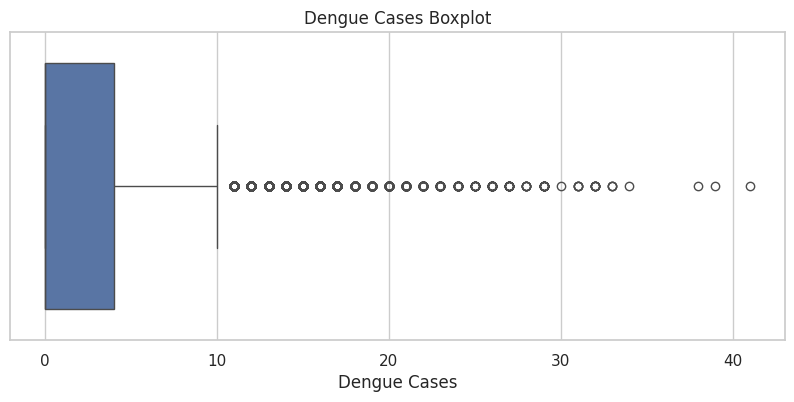


STEP 13A COMPLETED!


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

eda_df = df_clean.copy()

print("=" * 55)
print("       DENGUE CASES DISTRIBUTION")
print("=" * 55)

print("\n1. Dengue Cases Statistics:")
display(eda_df["dengue_cases"].describe())

print("\n2. Zero Case Records:")
print(
    (eda_df["dengue_cases"] == 0).sum()
)

print("\n3. Non-zero Case Records:")
print(
    (eda_df["dengue_cases"] > 0).sum()
)

print("\n4. Percentage of Zero Cases:")
print(
    round(
        (eda_df["dengue_cases"] == 0).mean() * 100,
        2
    ),
    "%"
)

# Dengue cases distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="dengue_cases",
    bins=30,
    kde=True
)

plt.title("Distribution of Weekly Dengue Cases")
plt.xlabel("Dengue Cases")
plt.ylabel("Frequency")

save_figure("dengue_cases_distribution.png")

plt.show()
plt.close()

# Boxplot
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=eda_df["dengue_cases"]
)

plt.title("Dengue Cases Boxplot")
plt.xlabel("Dengue Cases")

save_figure("dengue_cases_boxplot.png")

plt.show()
plt.close()

print("\nSTEP 13A COMPLETED!")

**Monthly & Seasonal Dengue Analysis**

       MONTHLY & SEASONAL DENGUE ANALYSIS

1. Monthly Average Dengue Cases:


,month,dengue_cases
0,1,0.008519
1,2,0.027642
2,3,0.063178
3,4,0.313178
4,5,0.842222
5,6,2.783333
6,7,6.855926
7,8,9.468561
8,9,8.482171
9,10,2.516296



2. Monthly Total Dengue Cases:


,month,dengue_cases
0,1,23
1,2,68
2,3,163
3,4,808
4,5,2274
5,6,7014
6,7,18511
7,8,24997
8,9,21884
9,10,6794


Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/monthly_average_dengue.png


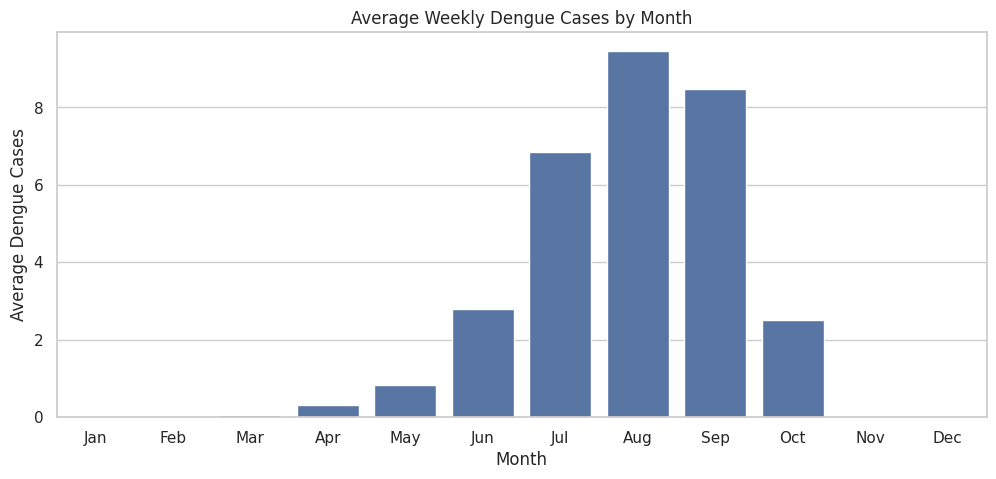

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/yearly_dengue_trend.png


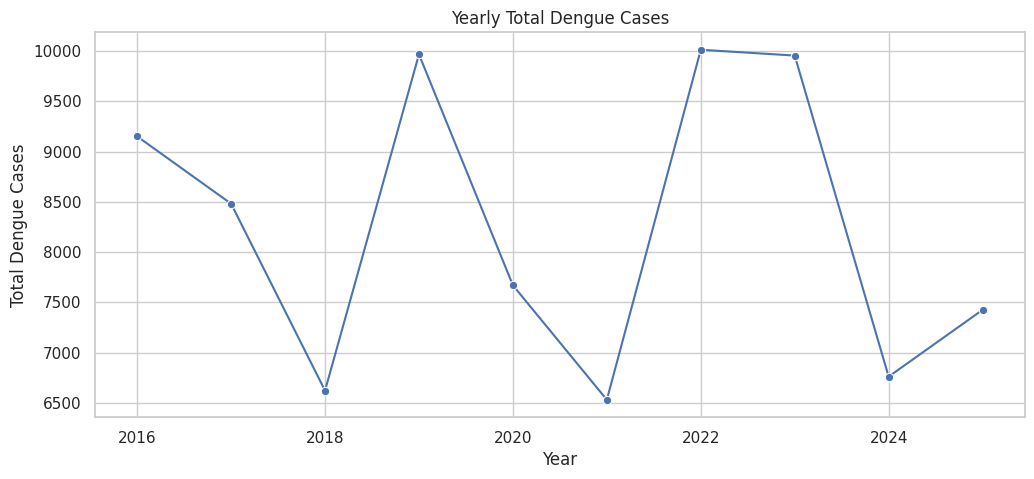


STEP 13B COMPLETED!


In [14]:
# ============================================
# STEP 13B: MONTHLY & SEASONAL ANALYSIS
# ============================================

eda_df["month"] = eda_df["date"].dt.month
eda_df["year"] = eda_df["date"].dt.year

# Month-wise average dengue cases
monthly_cases = (
    eda_df.groupby("month")["dengue_cases"]
    .mean()
    .reset_index()
)

# Month-wise total dengue cases
monthly_total = (
    eda_df.groupby("month")["dengue_cases"]
    .sum()
    .reset_index()
)

print("=" * 55)
print("       MONTHLY & SEASONAL DENGUE ANALYSIS")
print("=" * 55)

print("\n1. Monthly Average Dengue Cases:")
display(monthly_cases)

print("\n2. Monthly Total Dengue Cases:")
display(monthly_total)

# Month names
month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_cases["month_name"] = monthly_cases["month"].apply(
    lambda x: month_names[x - 1]
)

# Monthly average plot
plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_cases,
    x="month_name",
    y="dengue_cases"
)

plt.title("Average Weekly Dengue Cases by Month")
plt.xlabel("Month")
plt.ylabel("Average Dengue Cases")

save_figure("monthly_average_dengue.png")

plt.show()
plt.close()

# Year-wise dengue trend
yearly_cases = (
    eda_df.groupby("year")["dengue_cases"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=yearly_cases,
    x="year",
    y="dengue_cases",
    marker="o"
)

plt.title("Yearly Total Dengue Cases")
plt.xlabel("Year")
plt.ylabel("Total Dengue Cases")

save_figure("yearly_dengue_trend.png")

plt.show()
plt.close()

print("\nSTEP 13B COMPLETED!")

**Weather vs Dengue Relationship**

       WEATHER VS DENGUE ANALYSIS

1. Weather Correlation with Dengue:


,correlation
rainfall_mm,0.531192
relative_humidity_pct,0.526834
min_temp_c,0.342334
avg_temp_c,0.335319
max_temp_c,0.331619


Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/weather_dengue_correlation.png


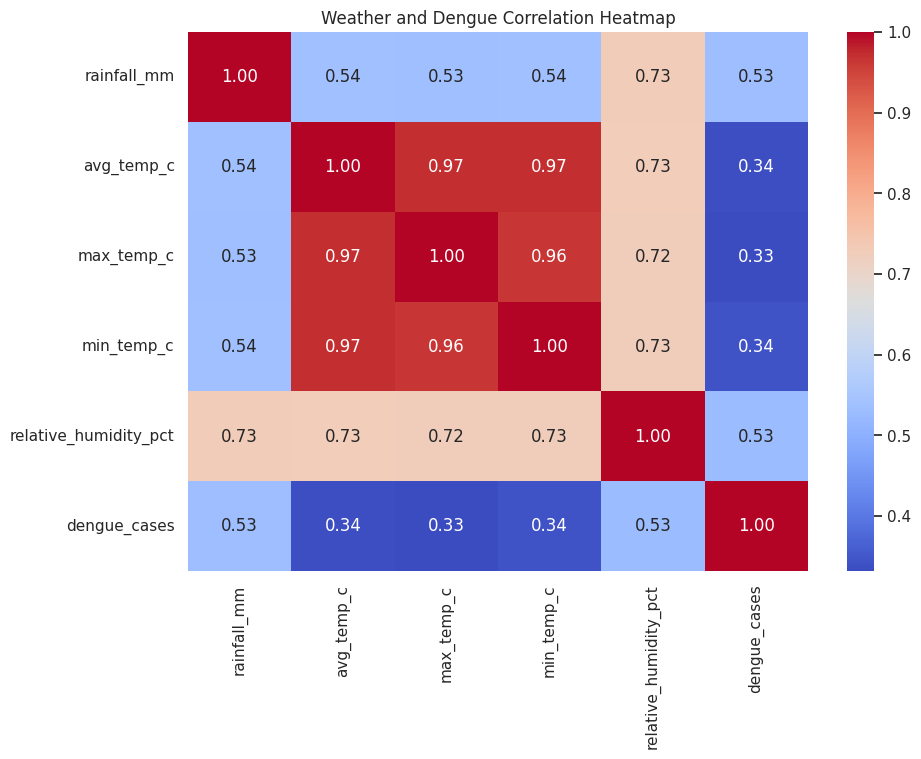

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/rainfall_mm_vs_dengue.png


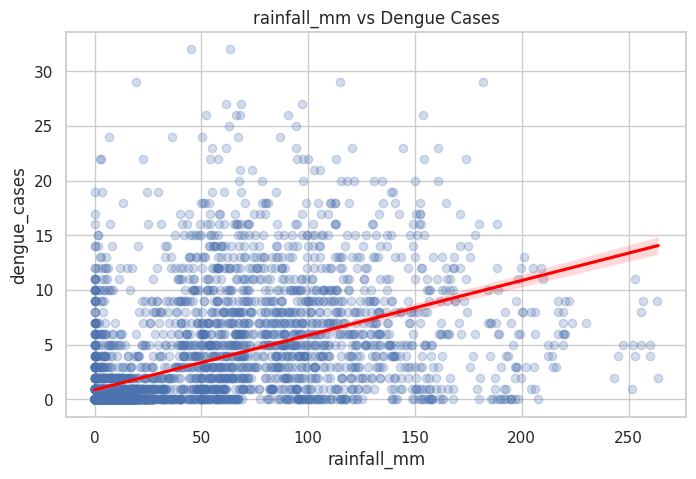

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/avg_temp_c_vs_dengue.png


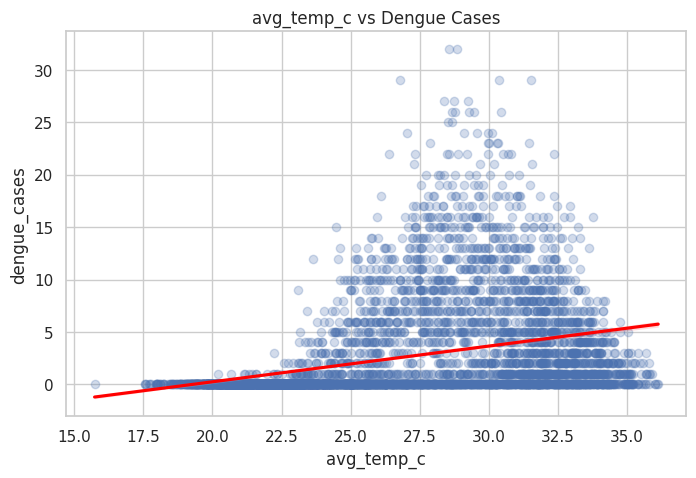

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/max_temp_c_vs_dengue.png


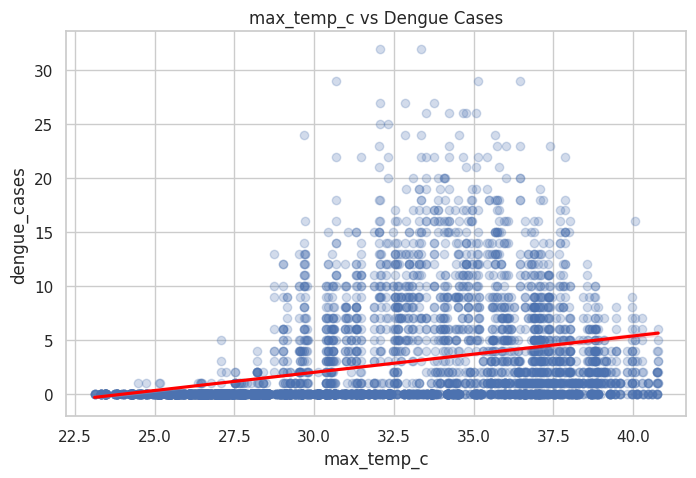

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/min_temp_c_vs_dengue.png


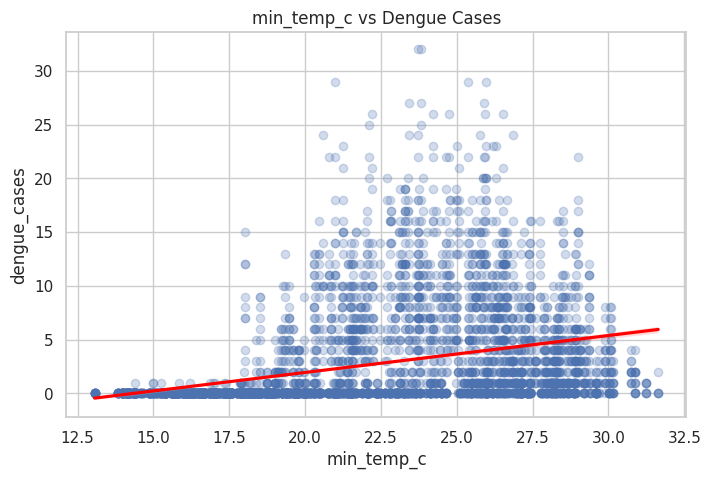

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/relative_humidity_pct_vs_dengue.png


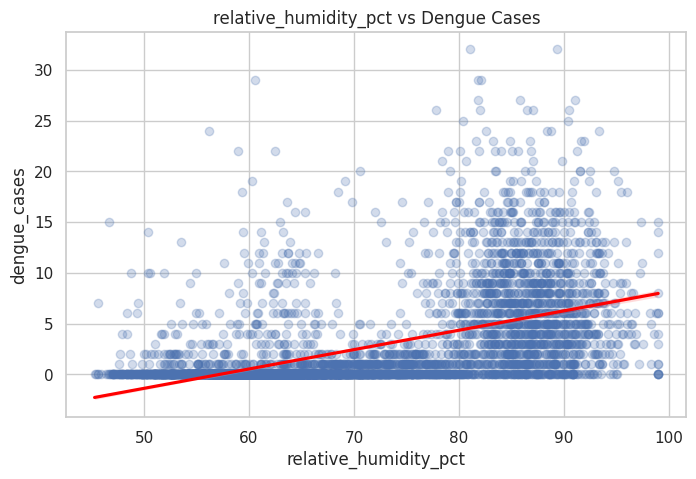


STEP 13C COMPLETED!


In [15]:
# ============================================
# STEP 13C: WEATHER VS DENGUE ANALYSIS
# ============================================

weather_cols = [
    "rainfall_mm",
    "avg_temp_c",
    "max_temp_c",
    "min_temp_c",
    "relative_humidity_pct"
]

print("=" * 55)
print("       WEATHER VS DENGUE ANALYSIS")
print("=" * 55)

# 1. Correlation with dengue cases
correlations = (
    eda_df[weather_cols + ["dengue_cases"]]
    .corr()["dengue_cases"]
    .drop("dengue_cases")
    .sort_values(ascending=False)
)

print("\n1. Weather Correlation with Dengue:")
display(correlations.to_frame("correlation"))

# 2. Correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    eda_df[weather_cols + ["dengue_cases"]].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Weather and Dengue Correlation Heatmap")

save_figure("weather_dengue_correlation.png")

plt.show()
plt.close()

# 3. Weather vs Dengue scatterplots
for col in weather_cols:

    plt.figure(figsize=(8, 5))

    sns.regplot(
        data=eda_df.sample(
            min(5000, len(eda_df)),
            random_state=42
        ),
        x=col,
        y="dengue_cases",
        scatter_kws={"alpha": 0.25},
        line_kws={"color": "red"}
    )

    plt.title(f"{col} vs Dengue Cases")

    save_figure(f"{col}_vs_dengue.png")

    plt.show()
    plt.close()

print("\nSTEP 13C COMPLETED!")

**Ward-wise Dengue Analysis**

       WARD-WISE DENGUE ANALYSIS

1. City-wise Average Dengue Cases:


,city,dengue_cases
0,Gazipur,3.178161
1,Dhaka South,2.604693
2,Dhaka North,2.586303
3,Chattogram,2.580460
4,Narayanganj,2.533716



2. Top 15 High Dengue Wards:


,city,ward_id,dengue_cases
0,Chattogram,CCC_Ward_03,2117
1,Dhaka North,DNCC_Ward_12,2085
2,Dhaka South,DSCC_Ward_04,2032
3,Dhaka North,DNCC_Ward_19,1961
4,Dhaka South,DSCC_Ward_06,1926
5,Chattogram,CCC_Ward_01,1915
6,Gazipur,GCC_Ward_02,1891
7,Gazipur,GCC_Ward_03,1857
8,Narayanganj,NCC_Ward_05,1833
9,Dhaka North,DNCC_Ward_18,1822



3. Bottom 15 Low Dengue Wards:


,city,ward_id,dengue_cases
45,Dhaka South,DSCC_Ward_09,1055
46,Dhaka South,DSCC_Ward_01,1028
47,Dhaka North,DNCC_Ward_14,1015
48,Dhaka South,DSCC_Ward_16,1010
49,Dhaka North,DNCC_Ward_06,996
50,Dhaka North,DNCC_Ward_04,984
51,Dhaka North,DNCC_Ward_17,979
52,Chattogram,CCC_Ward_02,956
53,Dhaka South,DSCC_Ward_17,922
54,Dhaka North,DNCC_Ward_20,902


Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/city_wise_dengue.png


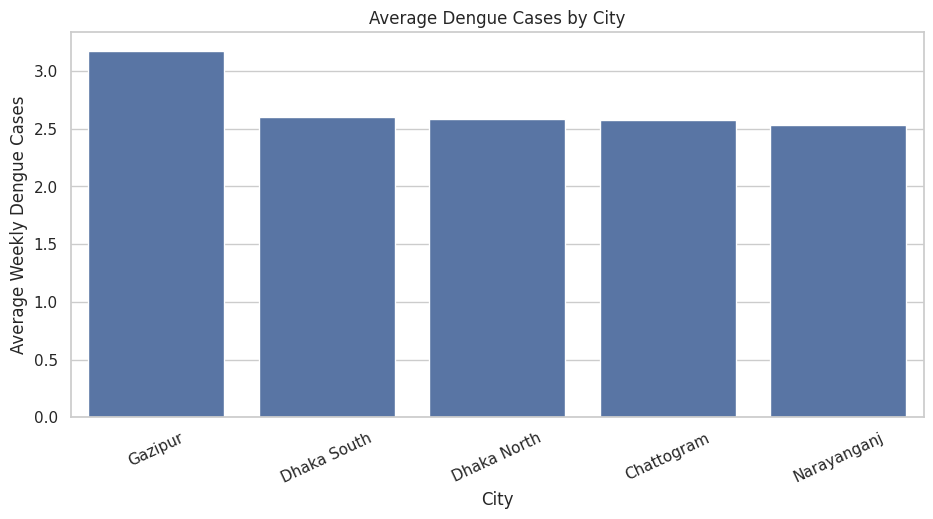

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/top_15_dengue_wards.png


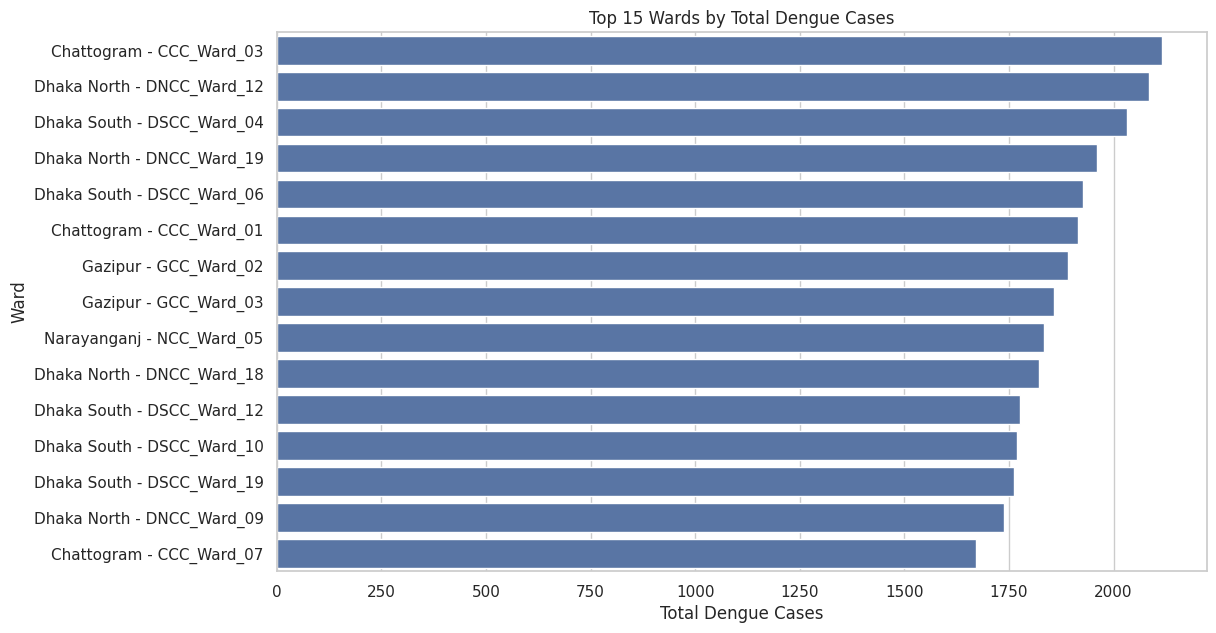


STEP 13D COMPLETED!


In [16]:
# ============================================
# STEP 13D: WARD-WISE DENGUE ANALYSIS
# ============================================

# City-wise average cases
city_cases = (
    eda_df.groupby("city")["dengue_cases"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Ward-wise total cases
ward_cases = (
    eda_df.groupby(["city", "ward_id"])["dengue_cases"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("=" * 55)
print("       WARD-WISE DENGUE ANALYSIS")
print("=" * 55)

print("\n1. City-wise Average Dengue Cases:")
display(city_cases)

print("\n2. Top 15 High Dengue Wards:")
display(ward_cases.head(15))

print("\n3. Bottom 15 Low Dengue Wards:")
display(ward_cases.tail(15))

# City-wise plot
plt.figure(figsize=(11, 5))

sns.barplot(
    data=city_cases,
    x="city",
    y="dengue_cases"
)

plt.title("Average Dengue Cases by City")
plt.xlabel("City")
plt.ylabel("Average Weekly Dengue Cases")
plt.xticks(rotation=25)

save_figure("city_wise_dengue.png")

plt.show()
plt.close()

# Top 15 ward plot
plt.figure(figsize=(12, 7))

top_wards = ward_cases.head(15).copy()
top_wards["ward_label"] = (
    top_wards["city"] + " - " + top_wards["ward_id"]
)

sns.barplot(
    data=top_wards,
    y="ward_label",
    x="dengue_cases"
)

plt.title("Top 15 Wards by Total Dengue Cases")
plt.xlabel("Total Dengue Cases")
plt.ylabel("Ward")

save_figure("top_15_dengue_wards.png")

plt.show()
plt.close()

print("\nSTEP 13D COMPLETED!")

**Chronological Data Splitting**

In [17]:

# ============================================
# STEP 14: CHRONOLOGICAL TRAIN-VALIDATION-TEST SPLIT
# ============================================

def chronological_split(data, horizon):
    data = data.copy()
    data["date"] = pd.to_datetime(data["date"])

    # Future target-এর তারিখ
    data["target_date"] = (
        data["date"] + pd.Timedelta(weeks=horizon)
    )

    # সব ward-এর common weekly dates
    unique_dates = sorted(data["date"].unique())
    n_dates = len(unique_dates)

    # 70% Train, 15% Validation, 15% Test
    train_end = pd.Timestamp(unique_dates[int(n_dates * 0.70) - 1])
    val_end = pd.Timestamp(unique_dates[int(n_dates * 0.85) - 1])

    # Purged chronological split
    train = data[
        (data["date"] <= train_end) &
        (data["target_date"] <= train_end)
    ].copy()

    val = data[
        (data["date"] > train_end) &
        (data["date"] <= val_end) &
        (data["target_date"] <= val_end)
    ].copy()

    test = data[
        data["date"] > val_end
    ].copy()

    return train, val, test, train_end, val_end


# 2-week split
train_2w, val_2w, test_2w, train_end_2w, val_end_2w = (
    chronological_split(model_data_2w, 2)
)

# 4-week split
train_4w, val_4w, test_4w, train_end_4w, val_end_4w = (
    chronological_split(model_data_4w, 4)
)


# Results
print("=" * 60)
print("       CHRONOLOGICAL DATA SPLITTING RESULTS")
print("=" * 60)

for name, train, val, test, train_end, val_end in [
    ("2-WEEK", train_2w, val_2w, test_2w,
     train_end_2w, val_end_2w),
    ("4-WEEK", train_4w, val_4w, test_4w,
     train_end_4w, val_end_4w)
]:
    print(f"\n{name} FORECAST")
    print("-" * 45)

    print("Train:", train.shape)
    print("Validation:", val.shape)
    print("Test:", test.shape)

    print("Train boundary:", train_end.date())
    print("Validation boundary:", val_end.date())

    print("\nDate ranges:")
    print("Train:", train["date"].min().date(),
          "to", train["date"].max().date())
    print("Validation:", val["date"].min().date(),
          "to", val["date"].max().date())
    print("Test:", test["date"].min().date(),
          "to", test["date"].max().date())

    assert train["target_date"].max() <= train_end
    assert val["target_date"].max() <= val_end
    assert train["date"].max() < val["date"].min()
    assert val["date"].max() < test["date"].min()

    print("Leakage boundary checks: PASSED")


# Save split datasets
for name, dataset in [
    ("train_2week.csv", train_2w),
    ("validation_2week.csv", val_2w),
    ("test_2week.csv", test_2w),
    ("train_4week.csv", train_4w),
    ("validation_4week.csv", val_4w),
    ("test_4week.csv", test_4w)
]:
    save_dataframe(dataset, name, folder=PROCESSED_DIR)

print("\nSTEP 14 COMPLETED!")


       CHRONOLOGICAL DATA SPLITTING RESULTS

2-WEEK FORECAST
---------------------------------------------
Train: (21360, 28)
Validation: (4500, 28)
Test: (4620, 28)
Train boundary: 2023-01-02
Validation boundary: 2024-06-24

Date ranges:
Train: 2016-02-29 to 2022-12-19
Validation: 2023-01-09 to 2024-06-10
Test: 2024-07-01 to 2025-12-15
Leakage boundary checks: PASSED

4-WEEK FORECAST
---------------------------------------------
Train: (21180, 28)
Validation: (4320, 28)
Test: (4620, 28)
Train boundary: 2022-12-26
Validation boundary: 2024-06-10

Date ranges:
Train: 2016-02-29 to 2022-11-28
Validation: 2023-01-02 to 2024-05-13
Test: 2024-06-17 to 2025-12-01
Leakage boundary checks: PASSED
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/train_2week.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/validation_2week.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/test_2week.csv
Saved successfully: /content/dr

**Preprocessing Pipeline**

In [18]:


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Categorical and numerical features
categorical_features = ["city", "ward_id"]

numeric_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Scikit-learn version compatibility
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=True
    )


def prepare_model_data(train, val, test, target):
    # Only use approved input features
    X_train = train[feature_columns].copy()
    X_val = val[feature_columns].copy()
    X_test = test[feature_columns].copy()

    y_train = train[target].copy()
    y_val = val[target].copy()
    y_test = test[target].copy()

    # Preprocessing: fit ONLY on training data
    preprocessor = ColumnTransformer(
        transformers=[
            ("categorical", encoder, categorical_features),
            ("numeric", "passthrough", numeric_features)
        ],
        remainder="drop"
    )

    X_train_processed = preprocessor.fit_transform(X_train)
    X_val_processed = preprocessor.transform(X_val)
    X_test_processed = preprocessor.transform(X_test)

    return (
        X_train_processed,
        X_val_processed,
        X_test_processed,
        y_train,
        y_val,
        y_test,
        preprocessor
    )


# Prepare 2-week data
(
    X_train_2w, X_val_2w, X_test_2w,
    y_train_2w, y_val_2w, y_test_2w,
    preprocessor_2w
) = prepare_model_data(
    train_2w, val_2w, test_2w, "target_2week"
)


# Prepare 4-week data
(
    X_train_4w, X_val_4w, X_test_4w,
    y_train_4w, y_val_4w, y_test_4w,
    preprocessor_4w
) = prepare_model_data(
    train_4w, val_4w, test_4w, "target_4week"
)


# Save preprocessing objects
save_model(preprocessor_2w, "preprocessor_2week.pkl")
save_model(preprocessor_4w, "preprocessor_4week.pkl")


# Results
print("=" * 60)
print("       PREPROCESSING RESULTS")
print("=" * 60)

print("\n2-WEEK FORECAST")
print("Train:", X_train_2w.shape)
print("Validation:", X_val_2w.shape)
print("Test:", X_test_2w.shape)

print("\n4-WEEK FORECAST")
print("Train:", X_train_4w.shape)
print("Validation:", X_val_4w.shape)
print("Test:", X_test_4w.shape)

print("\nCategorical features:", categorical_features)
print("Numerical feature count:", len(numeric_features))

print("\nMissing values check:")
print("2-week:",
      sum(pd.isna(y_train_2w)) +
      sum(pd.isna(y_val_2w)) +
      sum(pd.isna(y_test_2w)))

print("4-week:",
      sum(pd.isna(y_train_4w)) +
      sum(pd.isna(y_val_4w)) +
      sum(pd.isna(y_test_4w)))

print("\nSTEP 15 COMPLETED!")


Model saved: /content/drive/MyDrive/DengueGuard_AI/models/preprocessor_2week.pkl
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/preprocessor_4week.pkl
       PREPROCESSING RESULTS

2-WEEK FORECAST
Train: (21360, 88)
Validation: (4500, 88)
Test: (4620, 88)

4-WEEK FORECAST
Train: (21180, 88)
Validation: (4320, 88)
Test: (4620, 88)

Categorical features: ['city', 'ward_id']
Numerical feature count: 23

Missing values check:
2-week: 0
4-week: 0

STEP 15 COMPLETED!


**MODEL TRAINING & COMPARISON**


# 🦟 STEP 16: MODEL TRAINING & COMPARISON

## 🎯 Objective
Train and compare multiple Machine Learning regression models to predict future ward-level Dengue cases.

## 🤖 Models
1. XGBoost Regressor
2. LightGBM Regressor
3. CatBoost Regressor

## 🔮 Forecast Horizons
- 2-Week Dengue Prediction
- 4-Week Dengue Prediction

## 📊 Evaluation Metrics
- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- R² Score

## ⚙️ Training Strategy
- Chronological Train-Validation-Test Split
- Early Stopping
- Random State: 42
- Validation-based Model Comparison

## 💾 Model Storage
All trained models will be saved in Google Drive.

**Expected Output:** 6 trained regression models and a validation comparison report.


**XGBoost Model Training**

In [20]:

# ============================================================
# STEP 16A: XGBOOST MODEL TRAINING
# DengueGuard AI - 2 Week & 4 Week Forecast
# ============================================================

import numpy as np
import pandas as pd
import xgboost as xgb
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 65)
print("       DENGUEGUARD AI - XGBOOST MODEL TRAINING")
print("=" * 65)

# ------------------------------------------------------------
# 1. XGBOOST MODEL CONFIGURATION
# ------------------------------------------------------------

def create_xgb_model():

    model = xgb.XGBRegressor(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=3,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="reg:squarederror",
        eval_metric="rmse",
        random_state=42,
        n_jobs=-1,
        tree_method="hist"
    )

    return model


# ------------------------------------------------------------
# 2. TRAINING AND VALIDATION FUNCTION
# ------------------------------------------------------------

def train_xgboost(
    horizon,
    X_train,
    y_train,
    X_val,
    y_val
):

    print(f"\n{'=' * 55}")
    print(f"TRAINING XGBOOST - {horizon.upper()} FORECAST")
    print("=" * 55)

    model = create_xgb_model()

    print("\nTraining started...")

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    print("Training completed!")

    # Validation prediction
    val_predictions = model.predict(X_val)

    # Evaluation metrics
    mae = mean_absolute_error(
        y_val,
        val_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, val_predictions)
    )

    r2 = r2_score(
        y_val,
        val_predictions
    )

    print("\nVALIDATION PERFORMANCE")
    print("-" * 40)
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

    # Save trained model
    model_path = MODEL_DIR / f"xgboost_{horizon}.pkl"

    joblib.dump(model, model_path)

    print(f"\nModel saved: {model_path}")

    return model, {
        "Forecast": horizon,
        "Model": "XGBoost",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }


xgb_model_2w, result_2w = train_xgboost(
    horizon="2week",
    X_train=X_train_2w,
    y_train=y_train_2w,
    X_val=X_val_2w,
    y_val=y_val_2w
)

xgb_model_4w, result_4w = train_xgboost(
    horizon="4week",
    X_train=X_train_4w,
    y_train=y_train_4w,
    X_val=X_val_4w,
    y_val=y_val_4w
)

xgb_results = pd.DataFrame([
    result_2w,
    result_4w
])

print("\n" + "=" * 65)
print("       XGBOOST VALIDATION RESULTS")
print("=" * 65)

display(xgb_results.round(4))

save_dataframe(
    xgb_results,
    "xgboost_validation_results.csv",
    folder=REPORT_DIR
)

print("\n" + "=" * 65)
print("STEP 16A COMPLETED SUCCESSFULLY!")
print("=" * 65)

print("2-Week XGBoost: Trained and Saved")
print("4-Week XGBoost: Trained and Saved")


       DENGUEGUARD AI - XGBOOST MODEL TRAINING

TRAINING XGBOOST - 2WEEK FORECAST

Training started...
Training completed!

VALIDATION PERFORMANCE
----------------------------------------
MAE  : 0.9957
RMSE : 2.1194
R2   : 0.8085

Model saved: /content/drive/MyDrive/DengueGuard_AI/models/xgboost_2week.pkl

TRAINING XGBOOST - 4WEEK FORECAST

Training started...
Training completed!

VALIDATION PERFORMANCE
----------------------------------------
MAE  : 1.1825
RMSE : 2.4925
R2   : 0.7437

Model saved: /content/drive/MyDrive/DengueGuard_AI/models/xgboost_4week.pkl

       XGBOOST VALIDATION RESULTS


,Forecast,Model,MAE,RMSE,R2
0,2week,XGBoost,0.9957,2.1194,0.8085
1,4week,XGBoost,1.1825,2.4925,0.7437


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/xgboost_validation_results.csv

STEP 16A COMPLETED SUCCESSFULLY!
2-Week XGBoost: Trained and Saved
4-Week XGBoost: Trained and Saved


**LightGBM Model Training**

In [21]:
import lightgbm as lgb
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 65)
print("       DENGUEGUARD AI - LIGHTGBM MODEL TRAINING")
print("=" * 65)


def create_lgb_model():

    return lgb.LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        objective="regression",
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
def train_lightgbm(
    horizon,
    X_train,
    y_train,
    X_val,
    y_val
):

    print(f"\n{'=' * 55}")
    print(f"TRAINING LIGHTGBM - {horizon.upper()} FORECAST")
    print("=" * 55)

    model = create_lgb_model()

    print("\nTraining started...")

    model.fit(
        X_train,
        y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[
            lgb.early_stopping(50, verbose=False),
            lgb.log_evaluation(0)
        ]
    )

    print("Training completed!")

    # Validation predictions
    val_predictions = model.predict(X_val)

    # Evaluation metrics
    mae = mean_absolute_error(
        y_val,
        val_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, val_predictions)
    )

    r2 = r2_score(
        y_val,
        val_predictions
    )

    print("\nVALIDATION PERFORMANCE")
    print("-" * 40)
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

    # Save model
    model_path = MODEL_DIR / f"lightgbm_{horizon}.pkl"

    joblib.dump(model, model_path)

    print(f"\nModel saved: {model_path}")

    return model, {
        "Forecast": horizon,
        "Model": "LightGBM",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

lgb_model_2w, lgb_result_2w = train_lightgbm(
    horizon="2week",
    X_train=X_train_2w,
    y_train=y_train_2w,
    X_val=X_val_2w,
    y_val=y_val_2w
)
lgb_model_4w, lgb_result_4w = train_lightgbm(
    horizon="4week",
    X_train=X_train_4w,
    y_train=y_train_4w,
    X_val=X_val_4w,
    y_val=y_val_4w
)
lgb_results = pd.DataFrame([
    lgb_result_2w,
    lgb_result_4w
])

print("\n" + "=" * 65)
print("       LIGHTGBM VALIDATION RESULTS")
print("=" * 65)

display(lgb_results.round(4))

save_dataframe(
    lgb_results,
    "lightgbm_validation_results.csv",
    folder=REPORT_DIR
)
print("\n" + "=" * 65)
print("STEP 16B COMPLETED SUCCESSFULLY!")
print("=" * 65)

print("2-Week LightGBM: Trained and Saved")
print("4-Week LightGBM: Trained and Saved")


       DENGUEGUARD AI - LIGHTGBM MODEL TRAINING

TRAINING LIGHTGBM - 2WEEK FORECAST

Training started...
Training completed!

VALIDATION PERFORMANCE
----------------------------------------
MAE  : 0.9704
RMSE : 2.0561
R2   : 0.8198

Model saved: /content/drive/MyDrive/DengueGuard_AI/models/lightgbm_2week.pkl

TRAINING LIGHTGBM - 4WEEK FORECAST

Training started...
Training completed!

VALIDATION PERFORMANCE
----------------------------------------
MAE  : 1.2407
RMSE : 2.6202
R2   : 0.7168

Model saved: /content/drive/MyDrive/DengueGuard_AI/models/lightgbm_4week.pkl

       LIGHTGBM VALIDATION RESULTS


,Forecast,Model,MAE,RMSE,R2
0,2week,LightGBM,0.9704,2.0561,0.8198
1,4week,LightGBM,1.2407,2.6202,0.7168


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/lightgbm_validation_results.csv

STEP 16B COMPLETED SUCCESSFULLY!
2-Week LightGBM: Trained and Saved
4-Week LightGBM: Trained and Saved


**CatBoost Model Training**

In [22]:
import numpy as np
import pandas as pd
import joblib

from catboost import CatBoostRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 65)
print("       DENGUEGUARD AI - CATBOOST MODEL TRAINING")
print("=" * 65)


def create_catboost_model():

    return CatBoostRegressor(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function="RMSE",
        l2_leaf_reg=3,
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )


# ------------------------------------------------------------
# 2. TRAINING AND VALIDATION FUNCTION
# ------------------------------------------------------------

def train_catboost(
    horizon,
    X_train,
    y_train,
    X_val,
    y_val
):

    print(f"\n{'=' * 55}")
    print(f"TRAINING CATBOOST - {horizon.upper()} FORECAST")
    print("=" * 55)

    # CatBoost requires dense input for this pipeline
    X_train_dense = X_train.toarray()
    X_val_dense = X_val.toarray()

    model = create_catboost_model()

    print("\nTraining started...")

    model.fit(
        X_train_dense,
        y_train,
        eval_set=(X_val_dense, y_val),
        early_stopping_rounds=50,
        verbose=False
    )

    print("Training completed!")

    # Validation predictions
    val_predictions = model.predict(X_val_dense)

    # Evaluation metrics
    mae = mean_absolute_error(
        y_val,
        val_predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val, val_predictions)
    )

    r2 = r2_score(
        y_val,
        val_predictions
    )

    print("\nVALIDATION PERFORMANCE")
    print("-" * 40)
    print(f"MAE  : {mae:.4f}")
    print(f"RMSE : {rmse:.4f}")
    print(f"R2   : {r2:.4f}")

    # Save model
    model_path = MODEL_DIR / f"catboost_{horizon}.pkl"

    joblib.dump(model, model_path)

    print(f"\nModel saved: {model_path}")

    return model, {
        "Forecast": horizon,
        "Model": "CatBoost",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

cat_model_2w, cat_result_2w = train_catboost(
    horizon="2week",
    X_train=X_train_2w,
    y_train=y_train_2w,
    X_val=X_val_2w,
    y_val=y_val_2w
)


cat_model_4w, cat_result_4w = train_catboost(
    horizon="4week",
    X_train=X_train_4w,
    y_train=y_train_4w,
    X_val=X_val_4w,
    y_val=y_val_4w
)


cat_results = pd.DataFrame([
    cat_result_2w,
    cat_result_4w
])

print("\n" + "=" * 65)
print("       CATBOOST VALIDATION RESULTS")
print("=" * 65)

display(cat_results.round(4))

save_dataframe(
    cat_results,
    "catboost_validation_results.csv",
    folder=REPORT_DIR
)

print("\n" + "=" * 65)
print("STEP 16C COMPLETED SUCCESSFULLY!")
print("=" * 65)

print("2-Week CatBoost: Trained and Saved")
print("4-Week CatBoost: Trained and Saved")


       DENGUEGUARD AI - CATBOOST MODEL TRAINING

TRAINING CATBOOST - 2WEEK FORECAST

Training started...
Training completed!

VALIDATION PERFORMANCE
----------------------------------------
MAE  : 0.9528
RMSE : 1.9920
R2   : 0.8309

Model saved: /content/drive/MyDrive/DengueGuard_AI/models/catboost_2week.pkl

TRAINING CATBOOST - 4WEEK FORECAST

Training started...
Training completed!

VALIDATION PERFORMANCE
----------------------------------------
MAE  : 1.2789
RMSE : 2.5775
R2   : 0.7260

Model saved: /content/drive/MyDrive/DengueGuard_AI/models/catboost_4week.pkl

       CATBOOST VALIDATION RESULTS


,Forecast,Model,MAE,RMSE,R2
0,2week,CatBoost,0.9528,1.9920,0.8309
1,4week,CatBoost,1.2789,2.5775,0.7260


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/catboost_validation_results.csv

STEP 16C COMPLETED SUCCESSFULLY!
2-Week CatBoost: Trained and Saved
4-Week CatBoost: Trained and Saved


**Combined Model Comparison Report**

       COMBINED MODEL VALIDATION COMPARISON

ALL MODEL RESULTS:


,Forecast,Model,MAE,RMSE,R2
0,2week,CatBoost,0.9528,1.9920,0.8309
1,2week,LightGBM,0.9704,2.0561,0.8198
2,2week,XGBoost,0.9957,2.1194,0.8085
3,4week,XGBoost,1.1825,2.4925,0.7437
4,4week,LightGBM,1.2407,2.6202,0.7168
5,4week,CatBoost,1.2789,2.5775,0.7260



       BEST MODEL SELECTION


,Forecast,Model,MAE,RMSE,R2
0,2week,CatBoost,0.9528,1.9920,0.8309
1,4week,XGBoost,1.1825,2.4925,0.7437


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/all_models_validation_comparison.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/best_models_validation_report.csv
Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/2week_model_mae_comparison.png


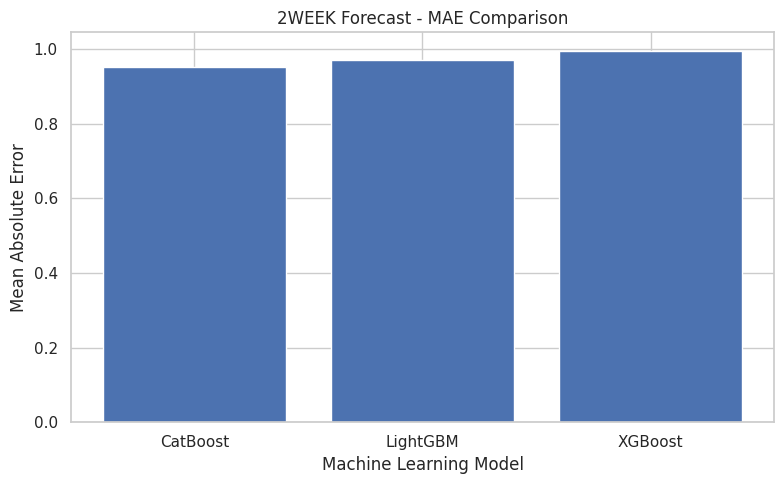

Figure saved: /content/drive/MyDrive/DengueGuard_AI/visualizations/4week_model_mae_comparison.png


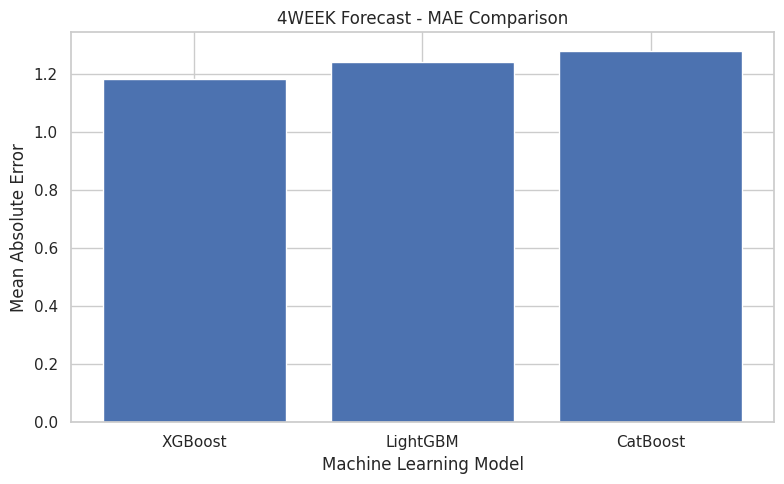


STEP 16D COMPLETED SUCCESSFULLY!
2week Best Model: CatBoost | MAE: 0.9528 | RMSE: 1.9920 | R2: 0.8309
4week Best Model: XGBoost | MAE: 1.1825 | RMSE: 2.4925 | R2: 0.7437


In [23]:
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 65)
print("       COMBINED MODEL VALIDATION COMPARISON")
print("=" * 65)

xgb_results = pd.read_csv(
    REPORT_DIR / "xgboost_validation_results.csv"
)

lgb_results = pd.read_csv(
    REPORT_DIR / "lightgbm_validation_results.csv"
)

cat_results = pd.read_csv(
    REPORT_DIR / "catboost_validation_results.csv"
)

all_results = pd.concat(
    [xgb_results, lgb_results, cat_results],
    ignore_index=True
)

all_results = all_results.sort_values(
    ["Forecast", "MAE"]
).reset_index(drop=True)


print("\nALL MODEL RESULTS:")
display(all_results.round(4))


best_models = (
    all_results
    .sort_values("MAE")
    .groupby("Forecast")
    .first()
    .reset_index()
)

print("\n" + "=" * 65)
print("       BEST MODEL SELECTION")
print("=" * 65)

display(best_models.round(4))

save_dataframe(
    all_results,
    "all_models_validation_comparison.csv",
    folder=REPORT_DIR
)

save_dataframe(
    best_models,
    "best_models_validation_report.csv",
    folder=REPORT_DIR
)

for horizon in ["2week", "4week"]:

    subset = all_results[
        all_results["Forecast"] == horizon
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        subset["Model"],
        subset["MAE"]
    )

    plt.title(
        f"{horizon.upper()} Forecast - MAE Comparison"
    )

    plt.xlabel("Machine Learning Model")
    plt.ylabel("Mean Absolute Error")

    plt.tight_layout()

    save_figure(
        f"{horizon}_model_mae_comparison.png"
    )

    plt.show()


print("\n" + "=" * 65)
print("STEP 16D COMPLETED SUCCESSFULLY!")
print("=" * 65)

for _, row in best_models.iterrows():

    print(
        f"{row['Forecast']} Best Model: {row['Model']} "
        f"| MAE: {row['MAE']:.4f} "
        f"| RMSE: {row['RMSE']:.4f} "
        f"| R2: {row['R2']:.4f}"
    )


**CatBoost Hyperparameter Tuning (2-Week)**


# STEP 18A: CATBOOST HYPERPARAMETER TUNING

## Objective
Optimize CatBoost hyperparameters to improve 2-week Dengue forecasting performance.

## Optimization Method
Randomized Parameter Search

## Evaluation Metrics
- R² Score (Higher is better)
- MAE (Lower is better)
- RMSE (Lower is better)

## Best Model Selection
The tuned model will be compared with the baseline CatBoost model using validation performance.


In [24]:
import numpy as np
import pandas as pd
import joblib

from catboost import CatBoostRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 65)
print("     CATBOOST HYPERPARAMETER TUNING - 2 WEEK")
print("=" * 65)


param_grid = {
    "iterations": [400, 600, 800, 1000],
    "depth": [4, 5, 6, 7, 8],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.07],
    "l2_leaf_reg": [1, 3, 5, 7, 9],
    "random_strength": [0.5, 1, 2, 3],
    "bagging_temperature": [0, 0.5, 1, 2]
}

# 12 different combinations
param_list = list(
    ParameterSampler(
        param_grid,
        n_iter=12,
        random_state=42
    )
)


X_train_dense = X_train_2w.toarray()
X_val_dense = X_val_2w.toarray()


baseline_predictions = cat_model_2w.predict(X_val_dense)

baseline_r2 = r2_score(
    y_val_2w, baseline_predictions
)

baseline_mae = mean_absolute_error(
    y_val_2w, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_val_2w, baseline_predictions)
)

print("\nBASELINE CATBOOST")
print("R2:", round(baseline_r2, 4))
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))


tuning_results = []
best_r2 = -float("inf")
best_model = None
best_params = None

for i, params in enumerate(param_list, start=1):

    print(f"\nTrial {i}/{len(param_list)}")
    print("Parameters:", params)

    model = CatBoostRegressor(
        **params,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    )

    model.fit(
        X_train_dense,
        y_train_2w,
        eval_set=(X_val_dense, y_val_2w),
        early_stopping_rounds=70,
        verbose=False
    )

    predictions = model.predict(X_val_dense)

    mae = mean_absolute_error(
        y_val_2w, predictions
    )

    rmse = np.sqrt(
        mean_squared_error(y_val_2w, predictions)
    )

    r2 = r2_score(
        y_val_2w, predictions
    )

    tuning_results.append({
        "Trial": i,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Parameters": str(params)
    })

    print(
        f"MAE={mae:.4f} | "
        f"RMSE={rmse:.4f} | "
        f"R2={r2:.4f}"
    )

    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_params = params

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "R2", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("BEST CATBOOST HYPERPARAMETERS")
print("=" * 65)

print(best_params)

print("\nBEST VALIDATION R2:", round(best_r2, 4))

print("\nTOP 5 TRIALS:")
display(tuning_df.head(5))


joblib.dump(
    best_model,
    MODEL_DIR / "catboost_2week_tuned.pkl"
)

save_dataframe(
    tuning_df,
    "catboost_2week_tuning_results.csv",
    folder=REPORT_DIR
)

print("\nTuned model saved successfully!")
print("STEP 18A COMPLETED!")


print("\nBASELINE VS TUNED R2")
print("Baseline R2:", round(baseline_r2, 4))
print("Tuned R2:", round(best_r2, 4))
print("R2 Improvement:", round(best_r2 - baseline_r2, 4))


     CATBOOST HYPERPARAMETER TUNING - 2 WEEK

BASELINE CATBOOST
R2: 0.8309
MAE: 0.9528
RMSE: 1.992

Trial 1/12
Parameters: {'random_strength': 2, 'learning_rate': 0.03, 'l2_leaf_reg': 7, 'iterations': 400, 'depth': 7, 'bagging_temperature': 2}
MAE=0.9365 | RMSE=1.9805 | R2=0.8328

Trial 2/12
Parameters: {'random_strength': 3, 'learning_rate': 0.01, 'l2_leaf_reg': 1, 'iterations': 400, 'depth': 8, 'bagging_temperature': 2}
MAE=0.9726 | RMSE=2.0311 | R2=0.8242

Trial 3/12
Parameters: {'random_strength': 0.5, 'learning_rate': 0.01, 'l2_leaf_reg': 7, 'iterations': 400, 'depth': 6, 'bagging_temperature': 0}
MAE=0.9652 | RMSE=2.0021 | R2=0.8291

Trial 4/12
Parameters: {'random_strength': 2, 'learning_rate': 0.03, 'l2_leaf_reg': 9, 'iterations': 600, 'depth': 7, 'bagging_temperature': 1}
MAE=0.9366 | RMSE=1.9846 | R2=0.8321

Trial 5/12
Parameters: {'random_strength': 2, 'learning_rate': 0.02, 'l2_leaf_reg': 3, 'iterations': 400, 'depth': 7, 'bagging_temperature': 1}
MAE=0.9425 | RMSE=1.9966 |

,Trial,MAE,RMSE,R2,Parameters
0,10,0.945351,1.970350,0.834515,"{'random_strength': 1, 'learning_rate': 0.02, ..."
1,8,0.940900,1.975045,0.833725,"{'random_strength': 0.5, 'learning_rate': 0.05..."
2,1,0.936475,1.980509,0.832804,"{'random_strength': 2, 'learning_rate': 0.03, ..."
3,11,0.947343,1.983214,0.832347,"{'random_strength': 2, 'learning_rate': 0.02, ..."
4,4,0.936601,1.984645,0.832105,"{'random_strength': 2, 'learning_rate': 0.03, ..."


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/catboost_2week_tuning_results.csv

Tuned model saved successfully!
STEP 18A COMPLETED!

BASELINE VS TUNED R2
Baseline R2: 0.8309
Tuned R2: 0.8345
R2 Improvement: 0.0037


**XGBoost Hyperparameter Tuning (4-Week)**


# STEP 18B: XGBOOST HYPERPARAMETER TUNING

## Objective
Improve 4-week Dengue forecasting performance.

## Model
XGBoost Regressor

## Optimization
Randomized Parameter Search

## Evaluation
R², MAE and RMSE

## Selection
Compare tuned XGBoost with baseline XGBoost.


In [25]:
import numpy as np
import pandas as pd
import joblib

from xgboost import XGBRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=" * 65)
print("     XGBOOST HYPERPARAMETER TUNING - 4 WEEK")
print("=" * 65)


baseline_model = joblib.load(MODEL_DIR / "xgboost_4week.pkl")

baseline_predictions = baseline_model.predict(X_val_4w)

baseline_r2 = r2_score(y_val_4w, baseline_predictions)
baseline_mae = mean_absolute_error(y_val_4w, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_val_4w, baseline_predictions))

print("\nBASELINE XGBOOST")
print("R2:", round(baseline_r2, 4))
print("MAE:", round(baseline_mae, 4))
print("RMSE:", round(baseline_rmse, 4))


param_grid = {
    "n_estimators": [300, 500, 700, 900],
    "max_depth": [3, 4, 5, 6, 7, 8],
    "learning_rate": [0.01, 0.02, 0.03, 0.05, 0.07],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "reg_alpha": [0, 0.01, 0.1, 0.5, 1],
    "reg_lambda": [0.5, 1, 2, 5],
    "gamma": [0, 0.1, 0.2, 0.5]
}

param_list = list(
    ParameterSampler(
        param_grid,
        n_iter=12,
        random_state=42
    )
)


tuning_results = []
best_r2 = -float("inf")
best_model = None
best_params = None

for i, params in enumerate(param_list, start=1):

    print(f"\nTrial {i}/{len(param_list)}")
    print("Parameters:", params)

    model = XGBRegressor(
        **params,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_4w, y_train_4w)

    predictions = model.predict(X_val_4w)

    mae = mean_absolute_error(y_val_4w, predictions)
    rmse = np.sqrt(mean_squared_error(y_val_4w, predictions))
    r2 = r2_score(y_val_4w, predictions)

    tuning_results.append({
        "Trial": i,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Parameters": str(params)
    })

    print(
        f"MAE={mae:.4f} | "
        f"RMSE={rmse:.4f} | "
        f"R2={r2:.4f}"
    )

    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_params = params


tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    "R2", ascending=False
).reset_index(drop=True)

print("\n" + "=" * 65)
print("BEST XGBOOST HYPERPARAMETERS")
print("=" * 65)

print(best_params)
print("\nBEST VALIDATION R2:", round(best_r2, 4))

print("\nTOP 5 TRIALS:")
display(tuning_df.head(5))

joblib.dump(
    best_model,
    MODEL_DIR / "xgboost_4week_tuned.pkl"
)

save_dataframe(
    tuning_df,
    "xgboost_4week_tuning_results.csv",
    folder=REPORT_DIR
)

print("\nTuned model saved successfully!")

print("\nBASELINE VS TUNED XGBOOST")
print("Baseline R2:", round(baseline_r2, 4))
print("Tuned R2:", round(best_r2, 4))
print("R2 Improvement:", round(best_r2 - baseline_r2, 4))

print("\nSTEP 18B COMPLETED!")


     XGBOOST HYPERPARAMETER TUNING - 4 WEEK

BASELINE XGBOOST
R2: 0.7437
MAE: 1.1825
RMSE: 2.4925

Trial 1/12
Parameters: {'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 0.7}
MAE=1.2620 | RMSE=2.5335 | R2=0.7353

Trial 2/12
Parameters: {'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha': 0, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.5, 'colsample_bytree': 0.7}
MAE=1.2224 | RMSE=2.5347 | R2=0.7350

Trial 3/12
Parameters: {'subsample': 0.9, 'reg_lambda': 5, 'reg_alpha': 1, 'n_estimators': 300, 'min_child_weight': 7, 'max_depth': 6, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.9}
MAE=1.1960 | RMSE=2.5394 | R2=0.7340

Trial 4/12
Parameters: {'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0.5, 'n_estimators': 900, 'min_child_weight': 3, 'max_depth': 7, 'learning_rate': 0.05, 'gamma': 0.2, 'colsample_bytree': 

,Trial,MAE,RMSE,R2,Parameters
0,7,1.175574,2.485944,0.745096,"{'subsample': 0.8, 'reg_lambda': 2, 'reg_alpha..."
1,4,1.181313,2.499781,0.742250,"{'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha..."
2,1,1.262005,2.533454,0.735260,"{'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha..."
3,2,1.222374,2.534667,0.735006,"{'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha..."
4,11,1.201603,2.534963,0.734944,"{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha..."


Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/xgboost_4week_tuning_results.csv

Tuned model saved successfully!

BASELINE VS TUNED XGBOOST
Baseline R2: 0.7437
Tuned R2: 0.7451
R2 Improvement: 0.0014

STEP 18B COMPLETED!



# STEP 18C: ADVANCED DENGUE LAG FEATURES
- Dengue lag 12 weeks
- Dengue lag 52 weeks
- Ward-wise historical dengue patterns
- Prevent future data leakage


In [26]:
import pandas as pd
import numpy as np

# Create a fresh copy
df_advanced = df_features.copy()

# Sort chronologically within each ward
df_advanced["date"] = pd.to_datetime(df_advanced["date"])

df_advanced = df_advanced.sort_values(
    ["city", "ward_id", "date"]
).reset_index(drop=True)

# Group by ward
ward_group = df_advanced.groupby(
    ["city", "ward_id"]
)["dengue_cases"]

# 12-week lag
df_advanced["dengue_lag_12"] = ward_group.shift(12)

# 52-week lag (previous year's same week)
df_advanced["dengue_lag_52"] = ward_group.shift(52)

# Check results
print("=" * 60)
print("ADVANCED DENGUE LAG FEATURES")
print("=" * 60)

print("\nNew Features:")
print("- dengue_lag_12")
print("- dengue_lag_52")

print("\nMissing Values:")
print(
    df_advanced[
        ["dengue_lag_12", "dengue_lag_52"]
    ].isnull().sum()
)

print("\nDataset Shape:", df_advanced.shape)

print("\nSample Output:")
display(
    df_advanced[
        [
            "city",
            "ward_id",
            "date",
            "dengue_cases",
            "dengue_lag_12",
            "dengue_lag_52"
        ]
    ].tail(10)
)

print("\nSTEP 18C COMPLETED!")


ADVANCED DENGUE LAG FEATURES

New Features:
- dengue_lag_12
- dengue_lag_52

Missing Values:
dengue_lag_12     720
dengue_lag_52    3120
dtype: int64

Dataset Shape: (31320, 30)

Sample Output:


,city,ward_id,date,dengue_cases,dengue_lag_12,dengue_lag_52
31310,Narayanganj,NCC_Ward_05,2025-10-27,0,8.0,0.0
31311,Narayanganj,NCC_Ward_05,2025-11-03,0,3.0,0.0
31312,Narayanganj,NCC_Ward_05,2025-11-10,0,5.0,0.0
31313,Narayanganj,NCC_Ward_05,2025-11-17,0,14.0,0.0
31314,Narayanganj,NCC_Ward_05,2025-11-24,0,10.0,0.0
31315,Narayanganj,NCC_Ward_05,2025-12-01,0,10.0,0.0
31316,Narayanganj,NCC_Ward_05,2025-12-08,0,11.0,0.0
31317,Narayanganj,NCC_Ward_05,2025-12-15,0,7.0,0.0
31318,Narayanganj,NCC_Ward_05,2025-12-22,0,10.0,0.0
31319,Narayanganj,NCC_Ward_05,2025-12-29,0,3.0,0.0



STEP 18C COMPLETED!



# STEP 18D: DENGUE ROLLING MEAN FEATURES
- 4-week rolling average
- 8-week rolling average
- 12-week rolling average
- Ward-wise calculation
- Leakage prevention using shift(1)


In [27]:
print("=" * 60)
print("DENGUE ROLLING MEAN FEATURE ENGINEERING")
print("=" * 60)

# Group by individual ward
ward_group = df_advanced.groupby(
    ["city", "ward_id"]
)["dengue_cases"]

# Previous 4 weeks average
df_advanced["dengue_roll_4"] = (
    ward_group.transform(
        lambda x: x.shift(1).rolling(
            window=4, min_periods=4
        ).mean()
    )
)

# Previous 8 weeks average
df_advanced["dengue_roll_8"] = (
    ward_group.transform(
        lambda x: x.shift(1).rolling(
            window=8, min_periods=8
        ).mean()
    )
)

# Previous 12 weeks average
df_advanced["dengue_roll_12"] = (
    ward_group.transform(
        lambda x: x.shift(1).rolling(
            window=12, min_periods=12
        ).mean()
    )
)

# Display missing values
rolling_columns = [
    "dengue_roll_4",
    "dengue_roll_8",
    "dengue_roll_12"
]

print("\nMissing Values:")
print(df_advanced[rolling_columns].isnull().sum())

print("\nDataset Shape:", df_advanced.shape)

print("\nSample Output:")

display(
    df_advanced[
        [
            "city",
            "ward_id",
            "date",
            "dengue_cases",
            "dengue_roll_4",
            "dengue_roll_8",
            "dengue_roll_12"
        ]
    ].tail(10)
)

print("\nSTEP 18D COMPLETED!")


DENGUE ROLLING MEAN FEATURE ENGINEERING

Missing Values:
dengue_roll_4     240
dengue_roll_8     480
dengue_roll_12    720
dtype: int64

Dataset Shape: (31320, 33)

Sample Output:


,city,ward_id,date,dengue_cases,dengue_roll_4,dengue_roll_8,dengue_roll_12
31310,Narayanganj,NCC_Ward_05,2025-10-27,0,3.50,6.500,6.833333
31311,Narayanganj,NCC_Ward_05,2025-11-03,0,1.00,5.250,6.166667
31312,Narayanganj,NCC_Ward_05,2025-11-10,0,0.25,4.000,5.916667
31313,Narayanganj,NCC_Ward_05,2025-11-17,0,0.00,2.625,5.500000
31314,Narayanganj,NCC_Ward_05,2025-11-24,0,0.00,1.750,4.333333
31315,Narayanganj,NCC_Ward_05,2025-12-01,0,0.00,0.500,3.500000
31316,Narayanganj,NCC_Ward_05,2025-12-08,0,0.00,0.125,2.666667
31317,Narayanganj,NCC_Ward_05,2025-12-15,0,0.00,0.000,1.750000
31318,Narayanganj,NCC_Ward_05,2025-12-22,0,0.00,0.000,1.166667
31319,Narayanganj,NCC_Ward_05,2025-12-29,0,0.00,0.000,0.333333



STEP 18D COMPLETED!



# STEP 18E: SEASONAL FEATURE ENGINEERING
- Week of year
- Cyclical sine encoding
- Cyclical cosine encoding
- Previous year dengue pattern


In [28]:
print("=" * 60)
print("SEASONAL FEATURE ENGINEERING")
print("=" * 60)

# Extract week number from date
week_number = df_advanced["date"].dt.isocalendar().week.astype(int)

# Cyclical encoding
df_advanced["week_sin"] = np.sin(
    2 * np.pi * week_number / 52.18
)

df_advanced["week_cos"] = np.cos(
    2 * np.pi * week_number / 52.18
)

# Previous year's same-period dengue cases
# Reuse the already created 52-week lag
df_advanced["previous_year_dengue"] = (
    df_advanced["dengue_lag_52"]
)

# Check results
seasonal_columns = [
    "week_sin",
    "week_cos",
    "previous_year_dengue"
]

print("\nNew Seasonal Features:")
print(seasonal_columns)

print("\nMissing Values:")
print(df_advanced[seasonal_columns].isnull().sum())

print("\nDataset Shape:", df_advanced.shape)

print("\nSample Output:")

display(
    df_advanced[
        [
            "date",
            "dengue_cases",
            "week_sin",
            "week_cos",
            "previous_year_dengue"
        ]
    ].tail(10)
)

print("\nSTEP 18E COMPLETED!")


SEASONAL FEATURE ENGINEERING

New Seasonal Features:
['week_sin', 'week_cos', 'previous_year_dengue']

Missing Values:
week_sin                   0
week_cos                   0
previous_year_dengue    3120
dtype: int64

Dataset Shape: (31320, 36)

Sample Output:


,date,dengue_cases,week_sin,week_cos,previous_year_dengue
31310,2025-10-27,0,-0.833263,0.552877,0.0
31311,2025-11-03,0,-0.760816,0.648967,0.0
31312,2025-11-10,0,-0.677352,0.735660,0.0
31313,2025-11-17,0,-0.584077,0.811698,0.0
31314,2025-11-24,0,-0.482344,0.875982,0.0
31315,2025-12-01,0,-0.373626,0.927579,0.0
31316,2025-12-08,0,-0.259497,0.965744,0.0
31317,2025-12-15,0,-0.141611,0.989922,0.0
31318,2025-12-22,0,-0.021673,0.999765,0.0
31319,2025-12-29,0,0.120123,0.992759,0.0



STEP 18E COMPLETED!



# STEP 18F: WEATHER FEATURE ENGINEERING
- Rainfall rolling average (4 and 8 weeks)
- Temperature-Humidity interaction
- Rainfall-Humidity interaction
- Temperature-Rainfall interaction
- Combined weather interaction


In [29]:
print("=" * 65)
print("WEATHER FEATURE ENGINEERING")
print("=" * 65)


rain_group = df_advanced.groupby(
    ["city", "ward_id"]
)["rainfall_mm"]

df_advanced["rainfall_roll_4"] = rain_group.transform(
    lambda x: x.shift(1).rolling(
        window=4, min_periods=4
    ).mean()
)

df_advanced["rainfall_roll_8"] = rain_group.transform(
    lambda x: x.shift(1).rolling(
        window=8, min_periods=8
    ).mean()
)


df_advanced["temp_humidity_interaction"] = (
    df_advanced["avg_temp_c"] *
    df_advanced["relative_humidity_pct"]
)

df_advanced["rainfall_humidity_interaction"] = (
    df_advanced["rainfall_mm"] *
    df_advanced["relative_humidity_pct"]
)

df_advanced["temp_rainfall_interaction"] = (
    df_advanced["avg_temp_c"] *
    df_advanced["rainfall_mm"]
)

df_advanced["temp_humidity_rainfall"] = (
    df_advanced["avg_temp_c"] *
    df_advanced["relative_humidity_pct"] *
    df_advanced["rainfall_mm"]
)

weather_columns = [
    "rainfall_roll_4",
    "rainfall_roll_8",
    "temp_humidity_interaction",
    "rainfall_humidity_interaction",
    "temp_rainfall_interaction",
    "temp_humidity_rainfall"
]

print("\nNew Weather Features:")
print(weather_columns)

print("\nMissing Values:")
print(df_advanced[weather_columns].isnull().sum())

print("\nDataset Shape:", df_advanced.shape)

print("\nSample Output:")

display(
    df_advanced[
        [
            "date",
            "avg_temp_c",
            "relative_humidity_pct",
            "rainfall_mm",
            "rainfall_roll_4",
            "rainfall_roll_8",
            "temp_humidity_interaction",
            "rainfall_humidity_interaction"
        ]
    ].tail(10)
)

print("\nSTEP 18F COMPLETED!")


WEATHER FEATURE ENGINEERING

New Weather Features:
['rainfall_roll_4', 'rainfall_roll_8', 'temp_humidity_interaction', 'rainfall_humidity_interaction', 'temp_rainfall_interaction', 'temp_humidity_rainfall']

Missing Values:
rainfall_roll_4                  240
rainfall_roll_8                  480
temp_humidity_interaction          0
rainfall_humidity_interaction      0
temp_rainfall_interaction          0
temp_humidity_rainfall             0
dtype: int64

Dataset Shape: (31320, 42)

Sample Output:


,date,avg_temp_c,relative_humidity_pct,rainfall_mm,rainfall_roll_4,rainfall_roll_8,temp_humidity_interaction,rainfall_humidity_interaction
31310,2025-10-27,23.60,62.56,0.00,0.7225,39.40250,1476.4160,0.0000
31311,2025-11-03,22.40,61.30,3.27,0.7225,34.29375,1373.1200,200.4510
31312,2025-11-10,21.57,56.00,0.56,1.5400,27.45750,1207.9200,31.3600
31313,2025-11-17,20.51,67.93,0.00,1.6800,17.24125,1393.2443,0.0000
31314,2025-11-24,20.75,58.07,0.00,0.9575,0.84000,1204.9525,0.0000
31315,2025-12-01,17.73,53.21,9.53,0.9575,0.84000,943.4133,507.0913
31316,2025-12-08,20.54,67.46,0.13,2.5225,2.03125,1385.6284,8.7698
31317,2025-12-15,21.98,65.93,8.24,2.4150,2.04750,1449.1414,543.2632
31318,2025-12-22,22.23,57.05,4.11,4.4750,2.71625,1268.2215,234.4755
31319,2025-12-29,21.76,55.04,0.51,5.5025,3.23000,1197.6704,28.0704



STEP 18F COMPLETED!


**Advanced Dataset Preparation**


# STEP 18G: ADVANCED DATASET PREPARATION
- Combine original and engineered features
- Remove duplicate feature
- Handle missing values
- Prepare 2-week and 4-week datasets
- Save advanced datasets


In [30]:
print("=" * 65)
print("ADVANCED DATASET PREPARATION")
print("=" * 65)


new_feature_columns = [
    "dengue_lag_12",
    "dengue_lag_52",
    "dengue_roll_4",
    "dengue_roll_8",
    "dengue_roll_12",
    "week_sin",
    "week_cos",
    "rainfall_roll_4",
    "rainfall_roll_8",
    "temp_humidity_interaction",
    "rainfall_humidity_interaction",
    "temp_rainfall_interaction",
    "temp_humidity_rainfall"
]

# Avoid duplicate previous_year_dengue
advanced_feature_columns = list(dict.fromkeys(
    feature_columns + new_feature_columns
))


required_columns = (
    advanced_feature_columns +
    ["date", "target_2week", "target_4week"]
)

missing_columns = [
    col for col in required_columns
    if col not in df_advanced.columns
]

assert not missing_columns, (
    f"Missing columns: {missing_columns}"
)

print("\nOriginal feature count:", len(feature_columns))
print("New feature count:", len(new_feature_columns))
print("Total advanced feature count:",
      len(advanced_feature_columns))


model_data_2w_advanced = df_advanced.dropna(
    subset=advanced_feature_columns + ["target_2week"]
)[
    ["date"] + advanced_feature_columns + ["target_2week"]
].copy()


model_data_4w_advanced = df_advanced.dropna(
    subset=advanced_feature_columns + ["target_4week"]
)[
    ["date"] + advanced_feature_columns + ["target_4week"]
].copy()


model_data_2w_advanced = (
    model_data_2w_advanced.reset_index(drop=True)
)

model_data_4w_advanced = (
    model_data_4w_advanced.reset_index(drop=True)
)



save_dataframe(
    model_data_2w_advanced,
    "advanced_model_data_2week.csv"
)

save_dataframe(
    model_data_4w_advanced,
    "advanced_model_data_4week.csv"
)


print("\n" + "=" * 65)
print("ADVANCED DATASET RESULTS")
print("=" * 65)

print("\n2-WEEK DATASET")
print("Shape:", model_data_2w_advanced.shape)
print("Missing values:",
      model_data_2w_advanced.isnull().sum().sum())

print("\n4-WEEK DATASET")
print("Shape:", model_data_4w_advanced.shape)
print("Missing values:",
      model_data_4w_advanced.isnull().sum().sum())

print("\nTotal Features:",
      len(advanced_feature_columns))

print("\nFeature List:")
print(advanced_feature_columns)

print("\nSTEP 18G COMPLETED!")


ADVANCED DATASET PREPARATION

Original feature count: 25
New feature count: 13
Total advanced feature count: 38
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_model_data_2week.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_model_data_4week.csv

ADVANCED DATASET RESULTS

2-WEEK DATASET
Shape: (28080, 40)
Missing values: 0

4-WEEK DATASET
Shape: (27960, 40)
Missing values: 0

Total Features: 38

Feature List:
['city', 'ward_id', 'population_density_sqkm', 'water_logging_risk_index', 'sanitation_score', 'avg_temp_c', 'max_temp_c', 'min_temp_c', 'rainfall_mm', 'relative_humidity_pct', 'dengue_cases', 'dengue_lag_1', 'dengue_lag_2', 'dengue_lag_4', 'dengue_lag_8', 'rainfall_sum_2w', 'rainfall_sum_4w', 'avg_temp_c_lag_1', 'avg_temp_c_lag_2', 'relative_humidity_pct_lag_1', 'relative_humidity_pct_lag_2', 'rainfall_mm_lag_1', 'rainfall_mm_lag_2', 'month', 'week_of_year', 'dengue_lag_12', 'dengue_lag_52', 'dengue_roll_4', 


# STEP 18H: ADVANCED CHRONOLOGICAL DATA SPLITTING
- 70% Training
- 15% Validation
- 15% Testing
- Target-date boundary protection
- Separate 2-week and 4-week splits


In [31]:
print("=" * 65)
print("ADVANCED CHRONOLOGICAL DATA SPLITTING")
print("=" * 65)

def advanced_chronological_split(data, horizon, prefix):

    data = data.copy()
    data["date"] = pd.to_datetime(data["date"])

    # Actual future target date
    data["target_date"] = (
        data["date"] + pd.to_timedelta(horizon, unit="W")
    )

    # Unique chronological dates
    unique_dates = np.sort(data["date"].unique())

    train_index = int(len(unique_dates) * 0.70)
    val_index = int(len(unique_dates) * 0.85)

    train_end = pd.Timestamp(unique_dates[train_index - 1])
    val_end = pd.Timestamp(unique_dates[val_index - 1])

    # Training: target must remain within training period
    train = data[
        (data["date"] <= train_end) &
        (data["target_date"] <= train_end)
    ].copy()

    # Validation: target must remain within validation period
    val = data[
        (data["date"] > train_end) &
        (data["date"] <= val_end) &
        (data["target_date"] <= val_end)
    ].copy()

    # Test: all remaining chronological observations
    test = data[
        data["date"] > val_end
    ].copy()

    # Remove helper column from model data
    for split_df in [train, val, test]:
        split_df.drop(columns=["target_date"], inplace=True)
        split_df.reset_index(drop=True, inplace=True)

    # Save all splits
    save_dataframe(train, f"{prefix}_train.csv")
    save_dataframe(val, f"{prefix}_validation.csv")
    save_dataframe(test, f"{prefix}_test.csv")

    # Display information
    print(f"\n{prefix.upper()} - {horizon} WEEK")
    print("-" * 55)

    print("Training:", train.shape)
    print("Validation:", val.shape)
    print("Testing:", test.shape)

    print("\nTrain date range:",
          train["date"].min(), "to", train["date"].max())

    print("Validation date range:",
          val["date"].min(), "to", val["date"].max())

    print("Test date range:",
          test["date"].min(), "to", test["date"].max())

    # Boundary checks
    assert train["date"].max() < val["date"].min()
    assert val["date"].max() < test["date"].min()

    return train, val, test


train_2w_adv, val_2w_adv, test_2w_adv = (
    advanced_chronological_split(
        model_data_2w_advanced,
        horizon=2,
        prefix="advanced_2week"
    )
)


train_4w_adv, val_4w_adv, test_4w_adv = (
    advanced_chronological_split(
        model_data_4w_advanced,
        horizon=4,
        prefix="advanced_4week"
    )
)

print("\n" + "=" * 65)
print("ALL CHRONOLOGICAL SPLITS COMPLETED SUCCESSFULLY!")
print("=" * 65)


ADVANCED CHRONOLOGICAL DATA SPLITTING
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_2week_train.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_2week_validation.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_2week_test.csv

ADVANCED_2WEEK - 2 WEEK
-------------------------------------------------------
Training: (19500, 40)
Validation: (4080, 40)
Testing: (4260, 40)

Train date range: 2017-01-02 00:00:00 to 2023-03-20 00:00:00
Validation date range: 2023-04-10 00:00:00 to 2024-07-22 00:00:00
Test date range: 2024-08-12 00:00:00 to 2025-12-15 00:00:00
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_4week_train.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_4week_validation.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/data/processed/advanced_4week_test.csv

ADVANCED_4WEEK - 4 WEEK
-------

**Preprocessing (Original vs Advanced Features)**

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import numpy as np
import joblib

print("=" * 65)
print("STEP 18I: ORIGINAL vs ADVANCED PREPROCESSING")
print("=" * 65)

categorical_features = ["city", "ward_id"]

def preprocess_feature_set(train_df, val_df, test_df, feature_cols, name):

    numeric_features = [
        col for col in feature_cols
        if col not in categorical_features
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            ("categorical",
             OneHotEncoder(handle_unknown="ignore"),
             categorical_features),

            ("numeric",
             "passthrough",
             numeric_features)
        ]
    )

    # Fit ONLY on training data
    X_train = preprocessor.fit_transform(
        train_df[feature_cols]
    )

    # Transform validation and test data
    X_val = preprocessor.transform(
        val_df[feature_cols]
    )

    X_test = preprocessor.transform(
        test_df[feature_cols]
    )

    print(f"\n{name}")
    print("-" * 55)
    print("Train shape:", X_train.shape)
    print("Validation shape:", X_val.shape)
    print("Test shape:", X_test.shape)

    print("Train target shape:", len(train_df))
    print("Validation target shape:", len(val_df))
    print("Test target shape:", len(test_df))

    # Save preprocessor
    save_model(preprocessor, f"preprocessor_{name}.pkl")

    return (
        X_train, X_val, X_test,
        train_df.filter(regex="^target_").copy(),
        val_df.filter(regex="^target_").copy(),
        test_df.filter(regex="^target_").copy(),
        preprocessor
    )



(
    X_train_2w_base, X_val_2w_base, X_test_2w_base,
    y_train_2w_base_df, y_val_2w_base_df, y_test_2w_base_df,
    preprocessor_2w_base
) = preprocess_feature_set(
    train_2w_adv,
    val_2w_adv,
    test_2w_adv,
    feature_columns,
    "2week_original"
)


(
    X_train_2w_adv, X_val_2w_adv, X_test_2w_adv,
    y_train_2w_adv_df, y_val_2w_adv_df, y_test_2w_adv_df,
    preprocessor_2w_adv
) = preprocess_feature_set(
    train_2w_adv,
    val_2w_adv,
    test_2w_adv,
    advanced_feature_columns,
    "2week_advanced"
)

(
    X_train_4w_base, X_val_4w_base, X_test_4w_base,
    y_train_4w_base_df, y_val_4w_base_df, y_test_4w_base_df,
    preprocessor_4w_base
) = preprocess_feature_set(
    train_4w_adv,
    val_4w_adv,
    test_4w_adv,
    feature_columns,
    "4week_original"
)

(
    X_train_4w_adv, X_val_4w_adv, X_test_4w_adv,
    y_train_4w_adv_df, y_val_4w_adv_df, y_test_4w_adv_df,
    preprocessor_4w_adv
) = preprocess_feature_set(
    train_4w_adv,
    val_4w_adv,
    test_4w_adv,
    advanced_feature_columns,
    "4week_advanced"
)


y_train_2w_base = train_2w_adv["target_2week"].values
y_val_2w_base   = val_2w_adv["target_2week"].values
y_test_2w_base  = test_2w_adv["target_2week"].values

y_train_2w_adv = y_train_2w_base.copy()
y_val_2w_adv   = y_val_2w_base.copy()
y_test_2w_adv  = y_test_2w_base.copy()

y_train_4w_base = train_4w_adv["target_4week"].values
y_val_4w_base   = val_4w_adv["target_4week"].values
y_test_4w_base  = test_4w_adv["target_4week"].values

y_train_4w_adv = y_train_4w_base.copy()
y_val_4w_adv   = y_val_4w_base.copy()
y_test_4w_adv  = y_test_4w_base.copy()


print("\n" + "=" * 65)
print("PREPROCESSING COMPLETED SUCCESSFULLY!")
print("=" * 65)

print("\nOriginal feature count:", len(feature_columns))
print("Advanced feature count:", len(advanced_feature_columns))

print("\nAll preprocessing objects saved successfully.")
print("All train/validation/test matrices are ready.")


STEP 18I: ORIGINAL vs ADVANCED PREPROCESSING

2week_original
-------------------------------------------------------
Train shape: (19500, 88)
Validation shape: (4080, 88)
Test shape: (4260, 88)
Train target shape: 19500
Validation target shape: 4080
Test target shape: 4260
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/preprocessor_2week_original.pkl

2week_advanced
-------------------------------------------------------
Train shape: (19500, 101)
Validation shape: (4080, 101)
Test shape: (4260, 101)
Train target shape: 19500
Validation target shape: 4080
Test target shape: 4260
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/preprocessor_2week_advanced.pkl

4week_original
-------------------------------------------------------
Train shape: (19320, 88)
Validation shape: (3960, 88)
Test shape: (4200, 88)
Train target shape: 19320
Validation target shape: 3960
Test target shape: 4200
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/preprocessor_4week_original

**Random Forest Multi-Output Model train**

In [33]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

print("=" * 65)
print("SINGLE MULTI-OUTPUT MODEL TRAINING")
print("=" * 65)

# 1. Common training data
keys = ["date", "city", "ward_id"]

train_common = train_2w_adv.merge(
    train_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

# 2. Input and two targets
X_train_raw = train_common[advanced_feature_columns]

y_train_multi = train_common[
    ["target_2week", "target_4week"]
].values

# 3. Preprocessing
categorical_features = ["city", "ward_id"]

numeric_features = [
    col for col in advanced_feature_columns
    if col not in categorical_features
]

multioutput_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         categorical_features),

        ("numeric",
         "passthrough",
         numeric_features)
    ]
)

X_train_multi = multioutput_preprocessor.fit_transform(
    X_train_raw
)

# 4. Create ONE Random Forest model
single_multioutput_model = RandomForestRegressor(
    n_estimators=300,
    max_features=0.8,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# 5. Train one model for two targets
print("\nTraining started...")

single_multioutput_model.fit(
    X_train_multi,
    y_train_multi
)

print("Training completed!")

# 6. Save model and preprocessor
save_model(
    single_multioutput_model,
    "random_forest_multioutput_2w_4w.pkl"
)

save_model(
    multioutput_preprocessor,
    "preprocessor_multioutput_2w_4w.pkl"
)

# 7. Model summary
print("\n" + "=" * 65)
print("TRAINING SUMMARY")
print("=" * 65)

print("Model: RandomForestRegressor")
print("Architecture: Multi-Output Regression")
print("Training samples:", len(X_train_multi))
print("Input features:", X_train_multi.shape[1])
print("Output targets:", y_train_multi.shape[1])
print("Target 1: 2-week dengue cases")
print("Target 2: 4-week dengue cases")

print("\nModel saved successfully!")
print("=" * 65)
print("STEP 18J COMPLETED!")
print("=" * 65)


SINGLE MULTI-OUTPUT MODEL TRAINING

Training started...
Training completed!
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/random_forest_multioutput_2w_4w.pkl
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/preprocessor_multioutput_2w_4w.pkl

TRAINING SUMMARY
Model: RandomForestRegressor
Architecture: Multi-Output Regression
Training samples: 19320
Input features: 101
Output targets: 2
Target 1: 2-week dengue cases
Target 2: 4-week dengue cases

Model saved successfully!
STEP 18J COMPLETED!


**Single Model Validation & Evaluation**

In [34]:

# ============================================================
# STEP 18K: SINGLE MULTI-OUTPUT MODEL VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("STEP 18K: SINGLE MODEL VALIDATION & EVALUATION")
print("=" * 70)


# ------------------------------------------------------------
# 1. PREPARE COMMON VALIDATION DATA
# ------------------------------------------------------------

keys = ["date", "city", "ward_id"]

val_common = val_2w_adv.merge(
    val_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

print("\nValidation samples:", len(val_common))


# ------------------------------------------------------------
# 2. PREPARE VALIDATION FEATURES AND TARGETS
# ------------------------------------------------------------

X_val_raw = val_common[advanced_feature_columns]

y_val_multi = val_common[
    ["target_2week", "target_4week"]
].values


# ------------------------------------------------------------
# 3. TRANSFORM USING TRAINED PREPROCESSOR
# ------------------------------------------------------------

X_val_multi = multioutput_preprocessor.transform(
    X_val_raw
)

print("Validation input shape:", X_val_multi.shape)
print("Validation target shape:", y_val_multi.shape)


# ------------------------------------------------------------
# 4. PREDICT BOTH HORIZONS USING ONE MODEL
# ------------------------------------------------------------

print("\nGenerating predictions...")

y_pred_multi = single_multioutput_model.predict(
    X_val_multi
)

print("Prediction completed!")
print("Prediction shape:", y_pred_multi.shape)


# ------------------------------------------------------------
# 5. EVALUATION FUNCTION
# ------------------------------------------------------------

def calculate_metrics(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


# ------------------------------------------------------------
# 6. EVALUATE 2-WEEK FORECAST
# ------------------------------------------------------------

metrics_2week = calculate_metrics(
    y_val_multi[:, 0],
    y_pred_multi[:, 0]
)


# ------------------------------------------------------------
# 7. EVALUATE 4-WEEK FORECAST
# ------------------------------------------------------------

metrics_4week = calculate_metrics(
    y_val_multi[:, 1],
    y_pred_multi[:, 1]
)


# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

results_df = pd.DataFrame([
    {
        "Forecast": "2-Week",
        **metrics_2week
    },
    {
        "Forecast": "4-Week",
        **metrics_4week
    }
])

print("\n" + "=" * 70)
print("SINGLE MULTI-OUTPUT MODEL - VALIDATION RESULTS")
print("=" * 70)

print(results_df.round(4).to_string(index=False))


# ------------------------------------------------------------
# 9. SAVE VALIDATION METRICS
# ------------------------------------------------------------

save_dataframe(
    results_df,
    "single_multioutput_validation_results.csv",
    folder=REPORT_DIR
)


# ------------------------------------------------------------
# 10. SAVE VALIDATION PREDICTIONS
# ------------------------------------------------------------

prediction_df = val_common[
    ["date", "city", "ward_id"]
].copy()

prediction_df["actual_2week"] = y_val_multi[:, 0]
prediction_df["predicted_2week"] = y_pred_multi[:, 0]

prediction_df["actual_4week"] = y_val_multi[:, 1]
prediction_df["predicted_4week"] = y_pred_multi[:, 1]

save_dataframe(
    prediction_df,
    "single_multioutput_validation_predictions.csv",
    folder=PREDICTION_DIR
)


# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("VALIDATION COMPLETED SUCCESSFULLY!")
print("=" * 70)

print(f"2-Week MAE : {metrics_2week['MAE']:.4f}")
print(f"2-Week RMSE: {metrics_2week['RMSE']:.4f}")
print(f"2-Week R2  : {metrics_2week['R2']:.4f}")

print("-" * 50)

print(f"4-Week MAE : {metrics_4week['MAE']:.4f}")
print(f"4-Week RMSE: {metrics_4week['RMSE']:.4f}")
print(f"4-Week R2  : {metrics_4week['R2']:.4f}")

print("\nModel: Single Multi-Output Random Forest")
print("Test dataset: Not used")

print("=" * 70)
print("STEP 18K COMPLETED!")
print("=" * 70)


STEP 18K: SINGLE MODEL VALIDATION & EVALUATION

Validation samples: 3900
Validation input shape: (3900, 101)
Validation target shape: (3900, 2)

Generating predictions...
Prediction completed!
Prediction shape: (3900, 2)

SINGLE MULTI-OUTPUT MODEL - VALIDATION RESULTS
Forecast    MAE   RMSE     R2
  2-Week 1.2258 2.3351 0.7940
  4-Week 1.7182 3.2047 0.6237
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/single_multioutput_validation_results.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/single_multioutput_validation_predictions.csv

VALIDATION COMPLETED SUCCESSFULLY!
2-Week MAE : 1.2258
2-Week RMSE: 2.3351
2-Week R2  : 0.7940
--------------------------------------------------
4-Week MAE : 1.7182
4-Week RMSE: 3.2047
4-Week R2  : 0.6237

Model: Single Multi-Output Random Forest
Test dataset: Not used
STEP 18K COMPLETED!


**Single Model vs Separate Models Comparison**

In [35]:

# ============================================================
# STEP 18L: SINGLE vs SEPARATE MODEL COMPARISON
# ============================================================

import numpy as np
import pandas as pd
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("=" * 70)
print("STEP 18L: SINGLE vs SEPARATE MODEL COMPARISON")
print("=" * 70)


# ------------------------------------------------------------
# 1. LOAD TRAINED SINGLE MODEL AND PREPROCESSOR
# ------------------------------------------------------------

single_model = joblib.load(
    MODEL_DIR / "random_forest_multioutput_2w_4w.pkl"
)

multi_preprocessor = joblib.load(
    MODEL_DIR / "preprocessor_multioutput_2w_4w.pkl"
)

print("\nSingle Multi-Output Model loaded successfully!")


# ------------------------------------------------------------
# 2. CREATE COMMON TRAINING AND VALIDATION DATA
# ------------------------------------------------------------

keys = ["date", "city", "ward_id"]

train_common = train_2w_adv.merge(
    train_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

val_common = val_2w_adv.merge(
    val_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

print("\nCommon Training samples:", len(train_common))
print("Common Validation samples:", len(val_common))


# ------------------------------------------------------------
# 3. PREPARE DATA
# ------------------------------------------------------------

X_train = multi_preprocessor.transform(
    train_common[advanced_feature_columns]
)

X_val = multi_preprocessor.transform(
    val_common[advanced_feature_columns]
)

y_train = train_common[
    ["target_2week", "target_4week"]
].values

y_val = val_common[
    ["target_2week", "target_4week"]
].values

print("\nTraining shape:", X_train.shape)
print("Validation shape:", X_val.shape)


# ------------------------------------------------------------
# 4. SINGLE MODEL PREDICTIONS
# ------------------------------------------------------------

print("\nGenerating Single Model predictions...")

single_predictions = single_model.predict(X_val)

print("Single Model predictions completed!")


# ------------------------------------------------------------
# 5. TRAIN TWO SEPARATE RANDOM FOREST MODELS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TRAINING SEPARATE MODELS")
print("=" * 70)

rf_params = {
    "n_estimators": 300,
    "max_features": 0.8,
    "min_samples_leaf": 2,
    "random_state": 42,
    "n_jobs": -1
}

# Separate 2-week model
separate_model_2w = RandomForestRegressor(**rf_params)

print("\nTraining 2-week model...")

separate_model_2w.fit(
    X_train,
    y_train[:, 0]
)

# Separate 4-week model
separate_model_4w = RandomForestRegressor(**rf_params)

print("Training 4-week model...")

separate_model_4w.fit(
    X_train,
    y_train[:, 1]
)

print("\nBoth Separate Models trained successfully!")


# ------------------------------------------------------------
# 6. SAVE SEPARATE MODELS
# ------------------------------------------------------------

save_model(
    separate_model_2w,
    "random_forest_separate_2week.pkl"
)

save_model(
    separate_model_4w,
    "random_forest_separate_4week.pkl"
)


# ------------------------------------------------------------
# 7. GENERATE SEPARATE MODEL PREDICTIONS
# ------------------------------------------------------------

separate_predictions_2w = separate_model_2w.predict(X_val)

separate_predictions_4w = separate_model_4w.predict(X_val)

print("\nSeparate Model predictions completed!")


# ------------------------------------------------------------
# 8. EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_predictions(y_true, y_pred):

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }



results = []

# Single Model - 2 weeks
results.append({
    "Architecture": "Single Multi-Output",
    "Horizon": "2-Week",
    **evaluate_predictions(
        y_val[:, 0],
        single_predictions[:, 0]
    )
})

# Separate Model - 2 weeks
results.append({
    "Architecture": "Separate Models",
    "Horizon": "2-Week",
    **evaluate_predictions(
        y_val[:, 0],
        separate_predictions_2w
    )
})

# Single Model - 4 weeks
results.append({
    "Architecture": "Single Multi-Output",
    "Horizon": "4-Week",
    **evaluate_predictions(
        y_val[:, 1],
        single_predictions[:, 1]
    )
})

# Separate Model - 4 weeks
results.append({
    "Architecture": "Separate Models",
    "Horizon": "4-Week",
    **evaluate_predictions(
        y_val[:, 1],
        separate_predictions_4w
    )
})


comparison_df = pd.DataFrame(results)

print("\n" + "=" * 70)
print("SINGLE vs SEPARATE MODEL - VALIDATION COMPARISON")
print("=" * 70)

print(comparison_df.round(4).to_string(index=False))


print("\n" + "=" * 70)
print("BEST ARCHITECTURE PER FORECAST HORIZON")
print("=" * 70)

for horizon in ["2-Week", "4-Week"]:

    subset = comparison_df[
        comparison_df["Horizon"] == horizon
    ]

    best = subset.loc[subset["MAE"].idxmin()]

    print(f"\n{horizon} Forecast:")
    print("Best Architecture:", best["Architecture"])
    print(f"MAE : {best['MAE']:.4f}")
    print(f"RMSE: {best['RMSE']:.4f}")
    print(f"R2  : {best['R2']:.4f}")

save_dataframe(
    comparison_df,
    "single_vs_separate_validation_comparison.csv",
    folder=REPORT_DIR
)
print("\n" + "=" * 70)
print("STEP 18L COMPLETED SUCCESSFULLY!")
print("=" * 70)

print("Single Multi-Output Model: Evaluated")
print("Separate 2-Week Model: Evaluated")
print("Separate 4-Week Model: Evaluated")

print("Validation data: Used")
print("Test data: NOT USED")

print("\nComparison report saved successfully!")
print("=" * 70)


STEP 18L: SINGLE vs SEPARATE MODEL COMPARISON

Single Multi-Output Model loaded successfully!

Common Training samples: 19320
Common Validation samples: 3900

Training shape: (19320, 101)
Validation shape: (3900, 101)

Generating Single Model predictions...
Single Model predictions completed!

TRAINING SEPARATE MODELS

Training 2-week model...
Training 4-week model...

Both Separate Models trained successfully!
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/random_forest_separate_2week.pkl
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/random_forest_separate_4week.pkl

Separate Model predictions completed!

SINGLE vs SEPARATE MODEL - VALIDATION COMPARISON
       Architecture Horizon    MAE   RMSE     R2
Single Multi-Output  2-Week 1.2258 2.3351 0.7940
    Separate Models  2-Week 1.2263 2.3693 0.7879
Single Multi-Output  4-Week 1.7182 3.2047 0.6237
    Separate Models  4-Week 1.6298 2.9819 0.6742

BEST ARCHITECTURE PER FORECAST HORIZON

2-Week Forecast:
Best Archit

**Hybrid Model Implementation & Validation**

In [36]:
print("=" * 75)
print("       STEP 18M: HYBRID MODEL IMPLEMENTATION & VALIDATION")
print("=" * 75)

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

# --------------------------------------------------
# 1. LOAD TRAINED MODELS
# --------------------------------------------------

single_multioutput_model = joblib.load(
    MODEL_DIR / "random_forest_multioutput_2w_4w.pkl"
)

separate_model_4w = joblib.load(
    MODEL_DIR / "random_forest_separate_4week.pkl"
)

multioutput_preprocessor = joblib.load(
    MODEL_DIR / "preprocessor_multioutput_2w_4w.pkl"
)

print("\nTrained models loaded successfully!")

# --------------------------------------------------
# 2. PREPARE VALIDATION DATA
# --------------------------------------------------

keys = ["date", "city", "ward_id"]

val_common = val_2w_adv.merge(
    val_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

X_val_hybrid = multioutput_preprocessor.transform(
    val_common[advanced_feature_columns]
)

y_val_2w = val_common["target_2week"].values
y_val_4w = val_common["target_4week"].values

print("\nValidation samples:", len(val_common))
print("Feature shape:", X_val_hybrid.shape)

# --------------------------------------------------
# 3. GENERATE HYBRID PREDICTIONS
# --------------------------------------------------

# 2-week prediction from Single Multi-Output Model
single_predictions = single_multioutput_model.predict(
    X_val_hybrid
)

hybrid_pred_2w = single_predictions[:, 0]

# 4-week prediction from Separate 4-Week Model
hybrid_pred_4w = separate_model_4w.predict(
    X_val_hybrid
)

# Dengue cases cannot be negative
hybrid_pred_2w = np.maximum(hybrid_pred_2w, 0)
hybrid_pred_4w = np.maximum(hybrid_pred_4w, 0)

print("\nHybrid predictions generated successfully!")

# --------------------------------------------------
# 4. EVALUATE HYBRID MODEL
# --------------------------------------------------

def evaluate_model(y_true, y_pred, horizon):

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Horizon": horizon,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    }

hybrid_results = []

hybrid_results.append(
    evaluate_model(y_val_2w, hybrid_pred_2w, "2-Week")
)

hybrid_results.append(
    evaluate_model(y_val_4w, hybrid_pred_4w, "4-Week")
)

hybrid_results_df = pd.DataFrame(hybrid_results)

print("\n" + "=" * 75)
print("              HYBRID MODEL VALIDATION RESULTS")
print("=" * 75)

print(hybrid_results_df.round(4).to_string(index=False))

save_dataframe(
    hybrid_results_df,
    "hybrid_model_validation_results.csv",
    REPORT_DIR
)

hybrid_predictions_df = val_common[keys].copy()

hybrid_predictions_df["actual_2week"] = y_val_2w
hybrid_predictions_df["predicted_2week"] = hybrid_pred_2w

hybrid_predictions_df["actual_4week"] = y_val_4w
hybrid_predictions_df["predicted_4week"] = hybrid_pred_4w

save_dataframe(
    hybrid_predictions_df,
    "hybrid_model_validation_predictions.csv",
    PREDICTION_DIR
)

print("\n" + "=" * 75)
print("STEP 18M COMPLETED SUCCESSFULLY!")
print("=" * 75)


       STEP 18M: HYBRID MODEL IMPLEMENTATION & VALIDATION

Trained models loaded successfully!

Validation samples: 3900
Feature shape: (3900, 101)

Hybrid predictions generated successfully!

              HYBRID MODEL VALIDATION RESULTS
Horizon    MAE   RMSE     R2
 2-Week 1.2258 2.3351 0.7940
 4-Week 1.6298 2.9819 0.6742
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/hybrid_model_validation_results.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/hybrid_model_validation_predictions.csv

STEP 18M COMPLETED SUCCESSFULLY!


**Advanced XGBoost Model Training**

In [37]:

# ======================================================================
# STEP 18N: ADVANCED FEATURE XGBOOST TRAINING
# ======================================================================

print("=" * 75)
print("       STEP 18N: ADVANCED FEATURE XGBOOST TRAINING")
print("=" * 75)

import numpy as np
import pandas as pd
import joblib

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. CHECK TRAINING DATA
# --------------------------------------------------

print("\n2-WEEK TRAINING SHAPE:", X_train_2w_adv.shape)
print("2-WEEK VALIDATION SHAPE:", X_val_2w_adv.shape)

print("\n4-WEEK TRAINING SHAPE:", X_train_4w_adv.shape)
print("4-WEEK VALIDATION SHAPE:", X_val_4w_adv.shape)

print("\nNumber of Advanced Features:", X_train_2w_adv.shape[1])

# --------------------------------------------------
# 2. DEFINE XGBOOST PARAMETERS
# --------------------------------------------------

xgb_params = {
    "n_estimators": 500,
    "max_depth": 6,
    "learning_rate": 0.05,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 3,
    "reg_alpha": 0.1,
    "reg_lambda": 1,
    "objective": "reg:squarederror",
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist"
}

# --------------------------------------------------
# 3. TRAIN 2-WEEK XGBOOST MODEL
# --------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING ADVANCED XGBOOST - 2 WEEK")
print("=" * 75)

xgb_model_2w_adv = XGBRegressor(**xgb_params)

xgb_model_2w_adv.fit(
    X_train_2w_adv,
    y_train_2w_adv,
    verbose=False
)

print("2-Week XGBoost training completed!")

# --------------------------------------------------
# 4. TRAIN 4-WEEK XGBOOST MODEL
# --------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING ADVANCED XGBOOST - 4 WEEK")
print("=" * 75)

xgb_model_4w_adv = XGBRegressor(**xgb_params)

xgb_model_4w_adv.fit(
    X_train_4w_adv,
    y_train_4w_adv,
    verbose=False
)

print("4-Week XGBoost training completed!")

# --------------------------------------------------
# 5. GENERATE VALIDATION PREDICTIONS
# --------------------------------------------------

xgb_pred_2w_adv = xgb_model_2w_adv.predict(X_val_2w_adv)
xgb_pred_4w_adv = xgb_model_4w_adv.predict(X_val_4w_adv)

# Dengue case predictions cannot be negative
xgb_pred_2w_adv = np.maximum(xgb_pred_2w_adv, 0)
xgb_pred_4w_adv = np.maximum(xgb_pred_4w_adv, 0)

# --------------------------------------------------
# 6. EVALUATION FUNCTION
# --------------------------------------------------

def evaluate_xgb(y_true, y_pred, horizon):

    return {
        "Model": "Advanced XGBoost",
        "Horizon": horizon,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

xgb_results = []

xgb_results.append(
    evaluate_xgb(y_val_2w_adv, xgb_pred_2w_adv, "2-Week")
)

xgb_results.append(
    evaluate_xgb(y_val_4w_adv, xgb_pred_4w_adv, "4-Week")
)

xgb_results_df = pd.DataFrame(xgb_results)

# --------------------------------------------------
# 7. DISPLAY RESULTS
# --------------------------------------------------

print("\n" + "=" * 75)
print("         ADVANCED XGBOOST VALIDATION RESULTS")
print("=" * 75)

print(xgb_results_df.round(4).to_string(index=False))

# --------------------------------------------------
# 8. SAVE TRAINED MODELS
# --------------------------------------------------

save_model(
    xgb_model_2w_adv,
    "xgboost_2week_advanced.pkl"
)

save_model(
    xgb_model_4w_adv,
    "xgboost_4week_advanced.pkl"
)


save_dataframe(
    xgb_results_df,
    "xgboost_advanced_validation_results.csv",
    REPORT_DIR
)

# Save predictions
xgb_predictions_df = pd.DataFrame({
    "actual_2week": y_val_2w_adv,
    "predicted_2week": xgb_pred_2w_adv,
    "actual_4week": y_val_4w_adv,
    "predicted_4week": xgb_pred_4w_adv
})

save_dataframe(
    xgb_predictions_df,
    "xgboost_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

print("\n" + "=" * 75)
print("STEP 18N COMPLETED SUCCESSFULLY!")
print("=" * 75)


       STEP 18N: ADVANCED FEATURE XGBOOST TRAINING

2-WEEK TRAINING SHAPE: (19500, 101)
2-WEEK VALIDATION SHAPE: (4080, 101)

4-WEEK TRAINING SHAPE: (19320, 101)
4-WEEK VALIDATION SHAPE: (3960, 101)

Number of Advanced Features: 101

TRAINING ADVANCED XGBOOST - 2 WEEK
2-Week XGBoost training completed!

TRAINING ADVANCED XGBOOST - 4 WEEK
4-Week XGBoost training completed!

         ADVANCED XGBOOST VALIDATION RESULTS
           Model Horizon    MAE   RMSE     R2
Advanced XGBoost  2-Week 1.2360 2.3122 0.7999
Advanced XGBoost  4-Week 1.6051 2.9659 0.6738
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/xgboost_2week_advanced.pkl
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/xgboost_4week_advanced.pkl
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/xgboost_advanced_validation_results.csv


ValueError: All arrays must be of the same length

In [38]:

# ======================================================================
# STEP 18N: FIX - SAVE XGBOOST PREDICTIONS SEPARATELY
# ======================================================================

print("=" * 75)
print("       SAVING XGBOOST VALIDATION PREDICTIONS")
print("=" * 75)

# 2-WEEK PREDICTIONS
xgb_predictions_2w = val_2w_adv[
    ["date", "city", "ward_id", "target_2week"]
].copy()

xgb_predictions_2w["predicted_2week"] = xgb_pred_2w_adv

xgb_predictions_2w.rename(
    columns={"target_2week": "actual_2week"},
    inplace=True
)

save_dataframe(
    xgb_predictions_2w,
    "xgboost_2week_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

# 4-WEEK PREDICTIONS
xgb_predictions_4w = val_4w_adv[
    ["date", "city", "ward_id", "target_4week"]
].copy()

xgb_predictions_4w["predicted_4week"] = xgb_pred_4w_adv

xgb_predictions_4w.rename(
    columns={"target_4week": "actual_4week"},
    inplace=True
)

save_dataframe(
    xgb_predictions_4w,
    "xgboost_4week_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

print("\n2-Week Prediction Shape:", xgb_predictions_2w.shape)
print("4-Week Prediction Shape:", xgb_predictions_4w.shape)

print("\n" + "=" * 75)
print("STEP 18N COMPLETED SUCCESSFULLY!")
print("=" * 75)


       SAVING XGBOOST VALIDATION PREDICTIONS
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/xgboost_2week_advanced_validation_predictions.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/xgboost_4week_advanced_validation_predictions.csv

2-Week Prediction Shape: (4080, 5)
4-Week Prediction Shape: (3960, 5)

STEP 18N COMPLETED SUCCESSFULLY!


**Advanced LightGBM Model Training**

In [39]:

# ======================================================================
# STEP 18O: ADVANCED FEATURE LIGHTGBM TRAINING
# ======================================================================

print("=" * 75)
print("       STEP 18O: ADVANCED FEATURE LIGHTGBM TRAINING")
print("=" * 75)

import numpy as np
import pandas as pd
import joblib

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. CHECK DATA
# --------------------------------------------------

print("\n2-WEEK TRAINING SHAPE:", X_train_2w_adv.shape)
print("2-WEEK VALIDATION SHAPE:", X_val_2w_adv.shape)

print("\n4-WEEK TRAINING SHAPE:", X_train_4w_adv.shape)
print("4-WEEK VALIDATION SHAPE:", X_val_4w_adv.shape)

print("\nAdvanced Features:", X_train_2w_adv.shape[1])

# --------------------------------------------------
# 2. LIGHTGBM PARAMETERS
# --------------------------------------------------

lgbm_params = {
    "n_estimators": 500,
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 20,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1,
    "objective": "regression",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": -1
}

# --------------------------------------------------
# 3. TRAIN 2-WEEK LIGHTGBM
# --------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING ADVANCED LIGHTGBM - 2 WEEK")
print("=" * 75)

lgbm_model_2w_adv = LGBMRegressor(**lgbm_params)

lgbm_model_2w_adv.fit(
    X_train_2w_adv,
    y_train_2w_adv
)

print("2-Week LightGBM training completed!")

# --------------------------------------------------
# 4. TRAIN 4-WEEK LIGHTGBM
# --------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING ADVANCED LIGHTGBM - 4 WEEK")
print("=" * 75)

lgbm_model_4w_adv = LGBMRegressor(**lgbm_params)

lgbm_model_4w_adv.fit(
    X_train_4w_adv,
    y_train_4w_adv
)

print("4-Week LightGBM training completed!")

# --------------------------------------------------
# 5. VALIDATION PREDICTIONS
# --------------------------------------------------

lgbm_pred_2w_adv = np.maximum(
    lgbm_model_2w_adv.predict(X_val_2w_adv), 0
)

lgbm_pred_4w_adv = np.maximum(
    lgbm_model_4w_adv.predict(X_val_4w_adv), 0
)

print("\nValidation predictions generated!")

# --------------------------------------------------
# 6. EVALUATION
# --------------------------------------------------

def evaluate_lgbm(y_true, y_pred, horizon):

    return {
        "Model": "Advanced LightGBM",
        "Horizon": horizon,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

lgbm_results = [
    evaluate_lgbm(y_val_2w_adv, lgbm_pred_2w_adv, "2-Week"),
    evaluate_lgbm(y_val_4w_adv, lgbm_pred_4w_adv, "4-Week")
]

lgbm_results_df = pd.DataFrame(lgbm_results)

print("\n" + "=" * 75)
print("       ADVANCED LIGHTGBM VALIDATION RESULTS")
print("=" * 75)

print(lgbm_results_df.round(4).to_string(index=False))

# --------------------------------------------------
# 7. SAVE MODELS
# --------------------------------------------------

save_model(
    lgbm_model_2w_adv,
    "lightgbm_2week_advanced.pkl"
)

save_model(
    lgbm_model_4w_adv,
    "lightgbm_4week_advanced.pkl"
)

# --------------------------------------------------
# 8. SAVE RESULTS
# --------------------------------------------------

save_dataframe(
    lgbm_results_df,
    "lightgbm_advanced_validation_results.csv",
    REPORT_DIR
)

# --------------------------------------------------
# 9. SAVE 2-WEEK PREDICTIONS
# --------------------------------------------------

lgbm_predictions_2w = val_2w_adv[
    ["date", "city", "ward_id", "target_2week"]
].copy()

lgbm_predictions_2w["predicted_2week"] = lgbm_pred_2w_adv

lgbm_predictions_2w.rename(
    columns={"target_2week": "actual_2week"},
    inplace=True
)

save_dataframe(
    lgbm_predictions_2w,
    "lightgbm_2week_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

# --------------------------------------------------
# 10. SAVE 4-WEEK PREDICTIONS
# --------------------------------------------------

lgbm_predictions_4w = val_4w_adv[
    ["date", "city", "ward_id", "target_4week"]
].copy()

lgbm_predictions_4w["predicted_4week"] = lgbm_pred_4w_adv

lgbm_predictions_4w.rename(
    columns={"target_4week": "actual_4week"},
    inplace=True
)

save_dataframe(
    lgbm_predictions_4w,
    "lightgbm_4week_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

print("\n" + "=" * 75)
print("STEP 18O COMPLETED SUCCESSFULLY!")
print("=" * 75)


       STEP 18O: ADVANCED FEATURE LIGHTGBM TRAINING

2-WEEK TRAINING SHAPE: (19500, 101)
2-WEEK VALIDATION SHAPE: (4080, 101)

4-WEEK TRAINING SHAPE: (19320, 101)
4-WEEK VALIDATION SHAPE: (3960, 101)

Advanced Features: 101

TRAINING ADVANCED LIGHTGBM - 2 WEEK
2-Week LightGBM training completed!

TRAINING ADVANCED LIGHTGBM - 4 WEEK
4-Week LightGBM training completed!

Validation predictions generated!

       ADVANCED LIGHTGBM VALIDATION RESULTS
            Model Horizon    MAE   RMSE     R2
Advanced LightGBM  2-Week 1.2669 2.3756 0.7888
Advanced LightGBM  4-Week 1.5515 2.8699 0.6946
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/lightgbm_2week_advanced.pkl
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/lightgbm_4week_advanced.pkl
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/lightgbm_advanced_validation_results.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/lightgbm_2week_advanced_validation_predictions.csv
Saved suc

**Advanced Feature CatBoost Training**

In [40]:

# ======================================================================
# STEP 18P: ADVANCED FEATURE CATBOOST TRAINING
# ======================================================================

print("=" * 75)
print("       STEP 18P: ADVANCED FEATURE CATBOOST TRAINING")
print("=" * 75)

import numpy as np
import pandas as pd
import joblib

from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. CHECK DATA
# --------------------------------------------------

print("\n2-WEEK TRAINING SHAPE:", X_train_2w_adv.shape)
print("2-WEEK VALIDATION SHAPE:", X_val_2w_adv.shape)

print("\n4-WEEK TRAINING SHAPE:", X_train_4w_adv.shape)
print("4-WEEK VALIDATION SHAPE:", X_val_4w_adv.shape)

print("\nAdvanced Features:", X_train_2w_adv.shape[1])

# --------------------------------------------------
# 2. CATBOOST PARAMETERS
# --------------------------------------------------

catboost_params = {
    "iterations": 500,
    "depth": 6,
    "learning_rate": 0.05,
    "loss_function": "RMSE",
    "l2_leaf_reg": 3,
    "random_seed": 42,
    "verbose": False,
    "allow_writing_files": False,
    "thread_count": -1
}

# --------------------------------------------------
# 3. TRAIN 2-WEEK CATBOOST
# --------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING ADVANCED CATBOOST - 2 WEEK")
print("=" * 75)

catboost_model_2w_adv = CatBoostRegressor(**catboost_params)

catboost_model_2w_adv.fit(
    X_train_2w_adv,
    y_train_2w_adv,
    verbose=False
)

print("2-Week CatBoost training completed!")

# --------------------------------------------------
# 4. TRAIN 4-WEEK CATBOOST
# --------------------------------------------------

print("\n" + "=" * 75)
print("TRAINING ADVANCED CATBOOST - 4 WEEK")
print("=" * 75)

catboost_model_4w_adv = CatBoostRegressor(**catboost_params)

catboost_model_4w_adv.fit(
    X_train_4w_adv,
    y_train_4w_adv,
    verbose=False
)

print("4-Week CatBoost training completed!")

# --------------------------------------------------
# 5. VALIDATION PREDICTIONS
# --------------------------------------------------

catboost_pred_2w_adv = np.maximum(
    catboost_model_2w_adv.predict(X_val_2w_adv), 0
)

catboost_pred_4w_adv = np.maximum(
    catboost_model_4w_adv.predict(X_val_4w_adv), 0
)

print("\nValidation predictions generated!")

# --------------------------------------------------
# 6. EVALUATION
# --------------------------------------------------

def evaluate_catboost(y_true, y_pred, horizon):

    return {
        "Model": "Advanced CatBoost",
        "Horizon": horizon,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

catboost_results = [
    evaluate_catboost(
        y_val_2w_adv,
        catboost_pred_2w_adv,
        "2-Week"
    ),
    evaluate_catboost(
        y_val_4w_adv,
        catboost_pred_4w_adv,
        "4-Week"
    )
]

catboost_results_df = pd.DataFrame(catboost_results)

print("\n" + "=" * 75)
print("       ADVANCED CATBOOST VALIDATION RESULTS")
print("=" * 75)

print(catboost_results_df.round(4).to_string(index=False))

# --------------------------------------------------
# 7. SAVE TRAINED MODELS
# --------------------------------------------------

save_model(
    catboost_model_2w_adv,
    "catboost_2week_advanced.pkl"
)

save_model(
    catboost_model_4w_adv,
    "catboost_4week_advanced.pkl"
)

# --------------------------------------------------
# 8. SAVE VALIDATION RESULTS
# --------------------------------------------------

save_dataframe(
    catboost_results_df,
    "catboost_advanced_validation_results.csv",
    REPORT_DIR
)

# --------------------------------------------------
# 9. SAVE 2-WEEK PREDICTIONS
# --------------------------------------------------

catboost_predictions_2w = val_2w_adv[
    ["date", "city", "ward_id", "target_2week"]
].copy()

catboost_predictions_2w["predicted_2week"] = catboost_pred_2w_adv

catboost_predictions_2w.rename(
    columns={"target_2week": "actual_2week"},
    inplace=True
)

save_dataframe(
    catboost_predictions_2w,
    "catboost_2week_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

# --------------------------------------------------
# 10. SAVE 4-WEEK PREDICTIONS
# --------------------------------------------------

catboost_predictions_4w = val_4w_adv[
    ["date", "city", "ward_id", "target_4week"]
].copy()

catboost_predictions_4w["predicted_4week"] = catboost_pred_4w_adv

catboost_predictions_4w.rename(
    columns={"target_4week": "actual_4week"},
    inplace=True
)

save_dataframe(
    catboost_predictions_4w,
    "catboost_4week_advanced_validation_predictions.csv",
    PREDICTION_DIR
)

print("\n" + "=" * 75)
print("STEP 18P COMPLETED SUCCESSFULLY!")
print("=" * 75)


       STEP 18P: ADVANCED FEATURE CATBOOST TRAINING

2-WEEK TRAINING SHAPE: (19500, 101)
2-WEEK VALIDATION SHAPE: (4080, 101)

4-WEEK TRAINING SHAPE: (19320, 101)
4-WEEK VALIDATION SHAPE: (3960, 101)

Advanced Features: 101

TRAINING ADVANCED CATBOOST - 2 WEEK
2-Week CatBoost training completed!

TRAINING ADVANCED CATBOOST - 4 WEEK
4-Week CatBoost training completed!

Validation predictions generated!

       ADVANCED CATBOOST VALIDATION RESULTS
            Model Horizon    MAE   RMSE     R2
Advanced CatBoost  2-Week 1.2150 2.2935 0.8031
Advanced CatBoost  4-Week 1.5556 2.9031 0.6875
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/catboost_2week_advanced.pkl
Model saved: /content/drive/MyDrive/DengueGuard_AI/models/catboost_4week_advanced.pkl
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/catboost_advanced_validation_results.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/catboost_2week_advanced_validation_predictions.csv
Saved suc

**ALL MODELS PERFORMANCE COMPARISON**

In [41]:

# ======================================================================
# STEP 18Q: ALL MODELS PERFORMANCE COMPARISON
# ======================================================================

print("=" * 80)
print("           STEP 18Q: ALL MODELS PERFORMANCE COMPARISON")
print("=" * 80)

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. LOAD ALL TRAINED MODELS
# --------------------------------------------------

print("\nLoading all trained models...")

single_model = joblib.load(
    MODEL_DIR / "random_forest_multioutput_2w_4w.pkl"
)

separate_2w = joblib.load(
    MODEL_DIR / "random_forest_separate_2week.pkl"
)

separate_4w = joblib.load(
    MODEL_DIR / "random_forest_separate_4week.pkl"
)

xgb_2w = joblib.load(
    MODEL_DIR / "xgboost_2week_advanced.pkl"
)

xgb_4w = joblib.load(
    MODEL_DIR / "xgboost_4week_advanced.pkl"
)

lgbm_2w = joblib.load(
    MODEL_DIR / "lightgbm_2week_advanced.pkl"
)

lgbm_4w = joblib.load(
    MODEL_DIR / "lightgbm_4week_advanced.pkl"
)

cat_2w = joblib.load(
    MODEL_DIR / "catboost_2week_advanced.pkl"
)

cat_4w = joblib.load(
    MODEL_DIR / "catboost_4week_advanced.pkl"
)

# Load preprocessing pipelines
multi_preprocessor = joblib.load(
    MODEL_DIR / "preprocessor_multioutput_2w_4w.pkl"
)

preprocessor_2w = joblib.load(
    MODEL_DIR / "preprocessor_2week_advanced.pkl"
)

preprocessor_4w = joblib.load(
    MODEL_DIR / "preprocessor_4week_advanced.pkl"
)

print("All models and preprocessors loaded successfully!")

# --------------------------------------------------
# 2. CREATE COMMON VALIDATION DATASET
# --------------------------------------------------

keys = ["date", "city", "ward_id"]

val_common = val_2w_adv.merge(
    val_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

print("\nCommon validation samples:", len(val_common))

# --------------------------------------------------
# 3. PREPROCESS COMMON VALIDATION DATA
# --------------------------------------------------

X_val_rf = multi_preprocessor.transform(
    val_common[advanced_feature_columns]
)

X_val_2w = preprocessor_2w.transform(
    val_common[advanced_feature_columns]
)

X_val_4w = preprocessor_4w.transform(
    val_common[advanced_feature_columns]
)

y_true_2w = val_common["target_2week"].values
y_true_4w = val_common["target_4week"].values

print("RF Feature Shape:", X_val_rf.shape)
print("2W Advanced Feature Shape:", X_val_2w.shape)
print("4W Advanced Feature Shape:", X_val_4w.shape)

# --------------------------------------------------
# 4. GENERATE PREDICTIONS FROM ALL MODELS
# --------------------------------------------------

print("\nGenerating predictions...")

# Random Forest predictions
single_pred = single_model.predict(X_val_rf)

single_pred_2w = np.maximum(single_pred[:, 0], 0)
single_pred_4w = np.maximum(single_pred[:, 1], 0)

separate_pred_2w = np.maximum(
    separate_2w.predict(X_val_rf), 0
)

separate_pred_4w = np.maximum(
    separate_4w.predict(X_val_rf), 0
)

# Hybrid predictions
hybrid_pred_2w = single_pred_2w.copy()
hybrid_pred_4w = separate_pred_4w.copy()

# Advanced XGBoost
xgb_pred_2w = np.maximum(xgb_2w.predict(X_val_2w), 0)
xgb_pred_4w = np.maximum(xgb_4w.predict(X_val_4w), 0)

# Advanced LightGBM
lgbm_pred_2w = np.maximum(lgbm_2w.predict(X_val_2w), 0)
lgbm_pred_4w = np.maximum(lgbm_4w.predict(X_val_4w), 0)

# Advanced CatBoost
cat_pred_2w = np.maximum(cat_2w.predict(X_val_2w), 0)
cat_pred_4w = np.maximum(cat_4w.predict(X_val_4w), 0)

print("All predictions generated successfully!")

# --------------------------------------------------
# 5. EVALUATION FUNCTION
# --------------------------------------------------

def calculate_metrics(y_true, y_pred, model_name, horizon):

    return {
        "Model": model_name,
        "Horizon": horizon,
        "Samples": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# --------------------------------------------------
# 6. COMPARE ALL MODELS
# --------------------------------------------------

comparison_results = []

# 2-Week
comparison_results.append(
    calculate_metrics(y_true_2w, single_pred_2w,
                      "Single Multi-Output RF", "2-Week")
)

comparison_results.append(
    calculate_metrics(y_true_2w, separate_pred_2w,
                      "Separate RF", "2-Week")
)

comparison_results.append(
    calculate_metrics(y_true_2w, hybrid_pred_2w,
                      "Hybrid RF", "2-Week")
)

comparison_results.append(
    calculate_metrics(y_true_2w, xgb_pred_2w,
                      "Advanced XGBoost", "2-Week")
)

comparison_results.append(
    calculate_metrics(y_true_2w, lgbm_pred_2w,
                      "Advanced LightGBM", "2-Week")
)

comparison_results.append(
    calculate_metrics(y_true_2w, cat_pred_2w,
                      "Advanced CatBoost", "2-Week")
)

# 4-Week
comparison_results.append(
    calculate_metrics(y_true_4w, single_pred_4w,
                      "Single Multi-Output RF", "4-Week")
)

comparison_results.append(
    calculate_metrics(y_true_4w, separate_pred_4w,
                      "Separate RF", "4-Week")
)

comparison_results.append(
    calculate_metrics(y_true_4w, hybrid_pred_4w,
                      "Hybrid RF", "4-Week")
)

comparison_results.append(
    calculate_metrics(y_true_4w, xgb_pred_4w,
                      "Advanced XGBoost", "4-Week")
)

comparison_results.append(
    calculate_metrics(y_true_4w, lgbm_pred_4w,
                      "Advanced LightGBM", "4-Week")
)

comparison_results.append(
    calculate_metrics(y_true_4w, cat_pred_4w,
                      "Advanced CatBoost", "4-Week")
)

comparison_df = pd.DataFrame(comparison_results)

# --------------------------------------------------
# 7. DISPLAY COMPARISON TABLE
# --------------------------------------------------

print("\n" + "=" * 80)
print("              COMPLETE MODEL COMPARISON")
print("=" * 80)

print(
    comparison_df.round(4).to_string(index=False)
)

# --------------------------------------------------
# 8. IDENTIFY BEST MODEL FOR EACH HORIZON
# --------------------------------------------------

print("\n" + "=" * 80)
print("                 BEST MODEL SELECTION")
print("=" * 80)

for horizon in ["2-Week", "4-Week"]:

    horizon_results = comparison_df[
        comparison_df["Horizon"] == horizon
    ]

    best_model = horizon_results.sort_values(
        by=["MAE", "RMSE"],
        ascending=True
    ).iloc[0]

    print(f"\nBest Model for {horizon}: {best_model['Model']}")
    print(f"MAE  : {best_model['MAE']:.4f}")
    print(f"RMSE : {best_model['RMSE']:.4f}")
    print(f"R2   : {best_model['R2']:.4f}")

# --------------------------------------------------
# 9. SAVE COMPARISON REPORT
# --------------------------------------------------

save_dataframe(
    comparison_df,
    "all_models_validation_comparison.csv",
    REPORT_DIR
)

# --------------------------------------------------
# 10. SAVE COMMON VALIDATION PREDICTIONS
# --------------------------------------------------

final_validation_predictions = val_common[keys].copy()

final_validation_predictions["actual_2week"] = y_true_2w
final_validation_predictions["single_rf_2week"] = single_pred_2w
final_validation_predictions["separate_rf_2week"] = separate_pred_2w
final_validation_predictions["hybrid_2week"] = hybrid_pred_2w
final_validation_predictions["xgboost_2week"] = xgb_pred_2w
final_validation_predictions["lightgbm_2week"] = lgbm_pred_2w
final_validation_predictions["catboost_2week"] = cat_pred_2w

final_validation_predictions["actual_4week"] = y_true_4w
final_validation_predictions["single_rf_4week"] = single_pred_4w
final_validation_predictions["separate_rf_4week"] = separate_pred_4w
final_validation_predictions["hybrid_4week"] = hybrid_pred_4w
final_validation_predictions["xgboost_4week"] = xgb_pred_4w
final_validation_predictions["lightgbm_4week"] = lgbm_pred_4w
final_validation_predictions["catboost_4week"] = cat_pred_4w

save_dataframe(
    final_validation_predictions,
    "all_models_common_validation_predictions.csv",
    PREDICTION_DIR
)

print("\n" + "=" * 80)
print("STEP 18Q COMPLETED SUCCESSFULLY!")
print("=" * 80)


           STEP 18Q: ALL MODELS PERFORMANCE COMPARISON

Loading all trained models...
All models and preprocessors loaded successfully!

Common validation samples: 3900
RF Feature Shape: (3900, 101)
2W Advanced Feature Shape: (3900, 101)
4W Advanced Feature Shape: (3900, 101)

Generating predictions...
All predictions generated successfully!

              COMPLETE MODEL COMPARISON
                 Model Horizon  Samples    MAE   RMSE     R2
Single Multi-Output RF  2-Week     3900 1.2258 2.3351 0.7940
           Separate RF  2-Week     3900 1.2263 2.3693 0.7879
             Hybrid RF  2-Week     3900 1.2258 2.3351 0.7940
      Advanced XGBoost  2-Week     3900 1.1786 2.2690 0.8055
     Advanced LightGBM  2-Week     3900 1.2141 2.3412 0.7929
     Advanced CatBoost  2-Week     3900 1.1614 2.2523 0.8083
Single Multi-Output RF  4-Week     3900 1.7182 3.2047 0.6237
           Separate RF  4-Week     3900 1.6298 2.9819 0.6742
             Hybrid RF  4-Week     3900 1.6298 2.9819 0.6742
     

**Final Test Evaluation**

In [42]:



print("=" * 80)
print("             STEP 18R: FINAL TEST EVALUATION")
print("=" * 80)

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



print("\nLoading selected best models...")

final_model_2w = joblib.load(
    MODEL_DIR / "catboost_2week_advanced.pkl"
)

final_model_4w = joblib.load(
    MODEL_DIR / "lightgbm_4week_advanced.pkl"
)

final_preprocessor_2w = joblib.load(
    MODEL_DIR / "preprocessor_2week_advanced.pkl"
)

final_preprocessor_4w = joblib.load(
    MODEL_DIR / "preprocessor_4week_advanced.pkl"
)

print("Selected models loaded successfully!")



keys = ["date", "city", "ward_id"]

test_common = test_2w_adv.merge(
    test_4w_adv[keys + ["target_4week"]],
    on=keys,
    how="inner"
)

print("\nCommon Test Samples:", len(test_common))



X_test_2w = final_preprocessor_2w.transform(
    test_common[advanced_feature_columns]
)

X_test_4w = final_preprocessor_4w.transform(
    test_common[advanced_feature_columns]
)

y_test_2w = test_common["target_2week"].values
y_test_4w = test_common["target_4week"].values

print("2-Week Test Shape:", X_test_2w.shape)
print("4-Week Test Shape:", X_test_4w.shape)

# --------------------------------------------------
# 4. GENERATE FINAL TEST PREDICTIONS
# --------------------------------------------------

print("\nGenerating final test predictions...")

final_pred_2w = np.maximum(
    final_model_2w.predict(X_test_2w), 0
)

final_pred_4w = np.maximum(
    final_model_4w.predict(X_test_4w), 0
)

print("Final predictions generated successfully!")



def calculate_test_metrics(y_true, y_pred, horizon, model_name):

    return {
        "Model": model_name,
        "Horizon": horizon,
        "Samples": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

final_test_results = [
    calculate_test_metrics(
        y_test_2w,
        final_pred_2w,
        "2-Week",
        "Advanced CatBoost"
    ),
    calculate_test_metrics(
        y_test_4w,
        final_pred_4w,
        "4-Week",
        "Advanced LightGBM"
    )
]

final_test_results_df = pd.DataFrame(final_test_results)



print("\n" + "=" * 80)
print("                FINAL TEST PERFORMANCE")
print("=" * 80)

print(final_test_results_df.round(4).to_string(index=False))

# --------------------------------------------------
# 7. SAVE FINAL TEST REPORT
# --------------------------------------------------

save_dataframe(
    final_test_results_df,
    "final_test_evaluation_results.csv",
    REPORT_DIR
)



final_test_predictions = test_common[keys].copy()

final_test_predictions["actual_2week"] = y_test_2w
final_test_predictions["predicted_2week"] = final_pred_2w

final_test_predictions["actual_4week"] = y_test_4w
final_test_predictions["predicted_4week"] = final_pred_4w

save_dataframe(
    final_test_predictions,
    "final_test_predictions.csv",
    PREDICTION_DIR
)


print("\n" + "=" * 80)
print("                  FINAL MODEL SUMMARY")
print("=" * 80)

print("2-Week Best Model : Advanced CatBoost")
print("4-Week Best Model : Advanced LightGBM")

print("\n2-Week Test R2:", round(final_test_results_df.iloc[0]["R2"], 4))
print("4-Week Test R2:", round(final_test_results_df.iloc[1]["R2"], 4))

print("\n" + "=" * 80)
print("STEP 18R COMPLETED SUCCESSFULLY!")
print("=" * 80)


             STEP 18R: FINAL TEST EVALUATION

Loading selected best models...
Selected models loaded successfully!

Common Test Samples: 4140
2-Week Test Shape: (4140, 101)
4-Week Test Shape: (4140, 101)

Generating final test predictions...
Final predictions generated successfully!

                FINAL TEST PERFORMANCE
            Model Horizon  Samples    MAE   RMSE     R2
Advanced CatBoost  2-Week     4140 1.1484 2.2232 0.7126
Advanced LightGBM  4-Week     4140 1.2832 2.5017 0.5507
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/reports/final_test_evaluation_results.csv
Saved successfully: /content/drive/MyDrive/DengueGuard_AI/predictions/final_test_predictions.csv

                  FINAL MODEL SUMMARY
2-Week Best Model : Advanced CatBoost
4-Week Best Model : Advanced LightGBM

2-Week Test R2: 0.7126
4-Week Test R2: 0.5507

STEP 18R COMPLETED SUCCESSFULLY!
